# EXP_03. ¿La forma de las curvas aporta, y cambia la respuesta con árboles?

**CRISP-DM: preparar, modelar y evaluar.** Una media de todo el ciclo puede ocultar
cambios de la curva. Añadimos cuatro descriptores definidos por calendario y
separamos dos preguntas: efecto del bloque y efecto de usar otro procedimiento.

**Cambio clave frente a EXP_02:** conservamos las seis variables **originales de
E2**; no sustituimos sus medias por las de T1. Añadimos forma temporal. Diseño
2 × 2: seis/diez numéricas × Ridge/HGB, más las referencias GLOBAL, MUN y MIX.

**Lector retrospectivo, cero ajustes.** Recalculamos cuatro variables desde
capturas y métricas de OOF **guardadas**. Verificamos selección desde scores
guardados, sin recalcular scores, entrenamientos, OOF ni las 59 predicciones finales.

Original: **29 de septiembre de 2026 en México** (la corrida UTC inicia el 30).
Adaptación: **8 de octubre**. Python histórico 3.12.14/scikit-learn 1.9.1; lectura
Python 3.13. Registro local exploratorio, posterior a EDA, sin sello externo.

**Recorrido:** hipótesis → capturas → cuatro descriptores → 2 × 2 → errores → decisión.
Basta este `.ipynb` en Colab, en orden: no necesita ZIP, Drive, Git ni otro cuaderno.
Dos bloques técnicos plegados; las operaciones científicas permanecen visibles.

## 1. Preparación e identidad de las fuentes

Colab prepara solo NumPy, pandas y Matplotlib con el perfil uv. Si cambia un módulo
cargado, pide reiniciar manualmente. En local no instala nada. «Mostrar código»
abre los bloques de soporte e insumos: no hay entrenamiento escondido.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T14:36:29.400134+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


| Insumo | Uso aquí | Límite |
| --- | --- | --- |
| Recortes de capturas originales | Recalcular dos series y cuatro descriptores | Derivados el 8/oct, no inscritos en septiembre |
| Seis variables E2 y etiquetas aparte | Conservar base y verificar rendimiento | No se usan 539 columnas como predictores |
| Particiones y scores interiores | Comprobar roles y selección | No repetir 3,800 ajustes |
| OOF guardadas | Recalcular métricas y diferencias | No son etiquetas adicionales |
| Controles, manifiesto y registro | Contrastar después del cálculo | No certifican fecha ante terceros |

Los recortes conservan NaN y seleccionan columnas, sensor y abril–octubre de 2025.
No filtran nubes ni usan rendimiento. Se reutilizan los recortes verificados del
8/oct: hashes originales y derivados separados. Sentinel NDVI está disponible en
el recorte, pero **no es una tercera serie temporal nueva** en esta hipótesis.

In [4]:
# @title Insumos: descompresión limitada, tamaño, SHA-256 y uso { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'variables_control': {'ruta_local': 'data/exp_03_variables_y_familias/variables_control.csv', 'sha256': '761074ef2be82713ef5f9f0134c33e85e76819f4ed4866340b2ad689de0b3385', 'bytes': 54486, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/variables_197.csv', 'bytes_zlib_base64': '...'}, 'mensuales_control': {'ruta_local': 'data/exp_03_variables_y_familias/mensuales_control.csv', 'sha256': 'de6c186266ce00d6ee182d91e4f33695c8509dcde8adcf0dfc7a75db55064b6d', 'bytes': 158404, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/medias_mensuales_197.csv', 'bytes_zlib_base64': '...'}, 'etiquetas': {'ruta_local': 'data/exp_03_variables_y_familias/etiquetas.csv', 'sha256': '42985c24e4669007667b7883ac34b18ba5a1e080c299724aaf6deebbab6e93ab', 'bytes': 2942, 'uso': 'etiquetas', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/etiquetas_138.csv', 'bytes_zlib_base64': 'eNp1VsuOHCEMvOdbWiMK/IDjKrvajJTsRNHe5///Ipil6e7E7hMzxsYulwvur8/fj5/398fHY/vz9vF6/3V/+/h8PD+fP16+vbx/f6aErdx4rvNGN8nt8k0TbWWueOMbJJ0/TJN0f2oXU54mPR1T+zamyyl1mlo36TwTqf9I12xkmkam15Nomop5JS86qJtq8VIHb/km5Jq0e7XqnlXDgtF2wHI6Ss+wWOTFyjlEJZcVq7fhlrK7SewY179Y6FS8NIuhReJ60bZvYkNbL5t0mk59LbWv/2HPjEVpr4DQgZ4ORIczcdhskuVsrSD2CqF6its6RdmtlxFG4HJkw3REYyN84CLdlPRimqmyhu3kU6pshCd4vBOjP8NDRHJPtfpexnF26S8LR9G1OuUiBhvNIzSFzdSYqWp0CrxOkKqBo+xuq3tq2sIM6mmkqgnYtQV7e6plI/DaUwdMc/TqmtWWQqa3UbXb62a6x9XTzaahULVVaWurnJ6sxZprREdiSPVVR2ZcpF0tkEaR7DAIiSPe4UvFs4MBvpTbIxeGck9AMZQbHoyA1aTwQnRRn4mD1sryZE8WgEN6gBbCkRHRCDkfEbrG5rUmG2tyXYZMuZBmNdVxu1Ws6Fo9PIY2w7tzUUyQmtujQpE2YIi1eyeh6KlH5Zh8FINPxEuChg544wU6ng6gY7rRpfz4/2s0vBpo5z84VDoMvXbnB2zIVfVCM8cBdZ063hribRIrWrIXWsYFsu/L1nJv8CFrCmWRWUZrvNsfXZsXfnJuk4RPDHS9Xj66X7BQu2BBXk5q6cIFU61PRV0vy6C45NUW3QSoQwKK51URqsiQZfc5gmrXcPK9Vk9ri146aCUU00Yhx5txWaprkoPmQ+b/I9xfdUhuLA=='}, 'oof': {'ruta_local': 'data/exp_03_variables_y_familias/oof.csv', 'sha256': '1a68054bbd11f8048fa0fb87529306d6703e11ab53e985888f3610a559b2d886', 'bytes': 756223, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'seleccion': {'ruta_local': 'data/exp_03_variables_y_familias/seleccion.csv', 'sha256': '293dc7413b61edb40c2952e5b2273ba012249deaefd60cd8d478b8e8a79b16d7', 'bytes': 27177, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/seleccion_interna.csv', 'bytes_zlib_base64': 'eNqlncuOLcexnud+CoNjQqi8Z3roEccGZ4ZBEOds2wIkURBlwIDhd/f3ZUVWb+igl3x6URps1u5eKyozLn/8ceGff/vXb3/67ce/ffvrt7//8V/++Ntffvzrn/747X/8r28//vXXv/36529//9tvv//4+7/89rdvv//yx7/8/dvf/vLb7//hv/zyn3+8+N8P/+eHH37901//568//PCf/uP1h/R/f/jxh/96/WHkOtu1rlLqvNb6kb9qtYzeU1t9tdly9VkdffXWxhwzjVHX/azWcaU8y8pzjnE/48NqyZVfXjPV+t9+CAnSP0pwPSL0q6Zcapqd3x7Jz+mltNnrKmP0fI255eql1VZmLY1vbfmWdfbcZ0XYVFYd97Nx9XXlnPooZaRHhPzpIfApJfWaekOM+4NnT7lfF+9/lTX6flb42ppr7mOtFF+WW+q8wFiljRE/l1vh/xdy9sEHPwKUTwVodfGzg5fItd0nkGrLmYeFayjrPoE2rnxlLqfUNfJ9W/xlG6vOVfmQcgvPOV3tuq411rjW8/310+/vlUvMs09eudxX3vmEhlR9lVTuW+GrRqm9cMstlysOpaxyLW+hpXzFz3FPKVUEQNJUQoD0Qg3RvtL4rjF4vVuANjrfsmpGMrThfltUpZbL889jrv1tdc2aeM1Vub6ZWzxrtV8oBlfBwY5HhH/Qw/SH67kDxC3o9soprfvd0OLSUuOuUYcrrKPNzHmhLJhEuZWAX20TC0IHMZFb+pYnTzGGqW62R4AXWoj4I3npZbZ5fzLvdl0jz9wL93N0fuXaa0M3EGyGznMh/FRvnkKJn0PmxoFOzDjPR4Ly6RHU2tHteaXUWr/yOQMsYWgcPb4LnW4Tl4Co9T4ozruXC8FKv1aI1BIGmBoKjGp8dwD1c08wChKPlkrhZG8D64l7RY+xsDTmsfrEu6Hb2MOVQjN0OpyStnDxF/EsYc/XVK3GOCeQX+hhmbxan8iBDscnc7RzlKFjQ+9uDU9X6lhKSmXOebVbN31j/oaj6Nco8SzjiDhP3iF/J0H6XAt0I3Xy07jScusSKok1Dp6k69xLTUt77TPhokYO++wJnS9jZnx46Ct+gCNQYSbH+kjwuR7i+7kBTmKgYucWku8x8H0Zr3+fQcf38e9YaMZdr3iG1+RxunZQCb/NhSA+gnEy45Hgcz3MOAM9GL6Vm74/ZBFTeCuutsabZRw9zrl4vSvNeLYSTmJkrj2P+LnW0cSFwSJs6c/3f+4OG44P09X/cxu3P76wq7Wwz5QXZnaf95hXxRvwZfxd3EHG9WT0Et+1SrjI7LUWtAqDOEpQ/lENvzuAa3ACeH3czFVLHDfK5QVMlBB/HerFGxeuF6XLNVSzGiQI4viudofqxs3hNvXbC/0sjwSfqyGC4mZR5DQnMXcfAfc9dKgGaozvNg4US6RQkfM4HlAB/8wpCBgpnPnV1KircK28wCPB52oI+LjUOPAGFrxuNex58IwwhAxhYqMY/Rb35cfflzCS+IPbMSynkBRAgEkTUybI5OMMPo/K3TCDtMb7XCIsJ4+h4SknQT48nbF+GCV58xEhAUPEZWPKQIAAVg1b4UPxhiCm8SHB54rIZYmDSt6eJwyaP/Iek6vA3UUIRNknERl/BDJpN2YDk2UUhB9GJUu/n008J2Jg35xqOzLUFy5RGIKlAYL4kBq3ya+iFxeavpDi1rGyMEcPDO0NWQ0GONOiPrY4GVwZkR4DAdmlRxPqK5fIhStxF6KsWwKi79SgwQ04gHhhcAhXUXWW6wrgir4SgUBNC6Da49k0mNaUVMePM/hcF3HG4lkVH2+bj+Ynwiv4hi8NgJYFq6ttPFgiXCe+jCA2uJsL24tnoB3A3CA289GPBC9C85oAAxBGAxpc97eBzIhNXb9stDouiS+fhG38XkTBxYtX/BcSlKNEXAIASy+NV/24hBc+Ec0p+CNg/+C9b4dw4Q3LRbwg9F4jLgbwjesg3iBrj6hw4SVAp8SFuBieEePxVGAZbzIkaC9j8/TE9+9d4dv53o4poiEZqwgPLBzGcY2Llw6peHHV5BI2HiUuBjngEsGB5/mR4HNF7AJg8BAeYaY7UcAbgIBRi+Wnp/O+OruV9SD5GL/WgaJkHOuM+MENEsexcj6DT3gkeIERwYIVfwQcTMexoXC8FllCmwCBiEw4QJwGX8pf5DswkKWRJIAuyXQCzKqRAm4cB0Dp4xLK5xgNLULzu6iwrRbuQPcL9FykZSscPq5LjzRJmPjS+xYu4jcOCkfsmdV4Vrw+0KRYcTwi1BdnML1GIBI+PXIVgChGphh5BCgX+YEM8PdVRB1qX/wl3FFTkeLnipkL8QRXNs8Z9H+riB9nUMgG0HsOALuugcdqMjkkDhK2emTIuCtgEMgHP3iyZn4N6IZPwnRv+Ayg0T6r7ps4kj9k+FQVSUww4Yxv48NnREKCi7eTACWgvhIOv6gaFyk9OcqMhyZtWrMpHzlSPDQyow5tW3R7hMifOqWiC0EdiavXDAy680iBR6qLm7/1HHU1DQIpcwH56L4kA0qL+gSC5sNwbygXgmJNjwQvQjQ4rYlSsgCo3MrALZj0mRCNyKMArVwG6EE3EVgVyyO0GqYR9T4EbjDhLTGUS1ebHwk+10aUnKQP77i6eenNXnDtJVUuh/sIECh7QhJVTVSfTE6ZyvbAiyQpsjZyB0yavFXYFhKMF35RUcmzifKEqV4jS718uVoMe7df5EYI+lxz8ipaj1sH3pAgcOd48FtU0AQgkjwWuNqI0e2R4fPkmZDADaNmmGa5ZcDGAc0Xlyk+SyebRGsRDPtZ4T14UmQzvHMV5342eXk8AqABtPYhwSu4iFvUwFG2fsAaWm/ArmYIEaIB65gpjo9DLu3QKuobdzFSEFDeFp9Copt08OMRoLxyS5sOI8aN4wSxJsC6aPnSrgKL+zMks1zGFZcOhuBh8bcRMB5hUdthkxXnDz14kT6D+cGFJAPyT/3wWNNcWjboJOs4mGUmIFWXwjGC5Phn7SsbkeNedy5TxLfj0cT5uSYScvJOkkE8H9wI3raNna6bB9+fzCsB0acxYgZGQFWKqJogADg+z1BEQ9YwpRqPBC8iNNB+yCMlOalxclJvhJfAJAMwq1REIlyHnut+hOup4mihfI1n3QRQmIPRcGaPBC/0kGSIFy5SULcP5vY1N+UgVQ4UjP8nQ6g7c82BoPlW9HeYX2K38awbx/JGCFd/vv+FGhYxOWJ0KbrgD3Bn3EPVD4NdAiHw7qJKU+oDXzXASySvT20ny9ab6Sw5mkeAV2rIL+D5gGY400BJQDGTOfmCeTQD9V+SI7gdAmawiYCjIbMjHgqfAbbd5rN0W+Wkz+slUuRj5INBAy3MbuFT8QYEK9DoYc2yX8crg6lyRAVRJuCu6kfKg6C5PKyDZB9n2x8JXughIZ/LxpUCrO53k7Xl9fZVph63gK5J0q1NkgWl3DYuJUcA5ZwEXhDfzeGxhzHzI8GrlEX6pGrPh7jD6pakPZKkA4xxMZcRzGiRAkeQVJHqTFHuPMgJm+Q9ZPg4yccZrFehmfi/pPMacDGYgSUsbpvNQ0nv6zUnSJJbOK/DHYIUuOspzX1FwpemL5Q34VIeX7BeJc/6TeTFA+acAyIt0Qp5J9nUyIGGAMZYAehdbjcS5Q0XgJf4ByJbi4fm/NuXFemULcPP/7a88j2RU71iXoZYNA9ZioJr+eiUyP8OuSAoHO+QAW81noHLATib2+m3Jsp8oBQ7pZdeeCR4UV4pOjGdElpc78NEmCJZyQMT+RPxhrSq+DG3p5RiZccgmk0U4lkaBi/cFx85HhFeqaJ0FGD11qlbF/UzWbaCBDCUPG++I0t7cm6hn6j9SDsM4MGPS7oA8eTvGROZH9fwefa8qxubplnyRwccVHFwMy0Kc0Q7EQuDNPgGOphCCBJ2FblE3oTCgJ+5m6SKPQK8yFn4QfN2wtDMN6UJ3MKeOMHN50UWIYbBIgfagLXHMxwJ4dpzuSI0415Qp12kAvwfAV4VWIr8fd6pAb61R4HFnEdLF7lE0FcFZ90xYQUWuqwIIk4f+w8BDoapj+p4tfwI8DlCRABwSJeZNgcOn2z5UA28+gFjvBohNEmfcRpB3YlULs/AzDeeKc61CXbd0iPB59lK3l9nZsBF9nmKXPyrbLtMc+CFAe64LCsmCfV4luQq0trKH88AWsB2vz+viM0/v6yvoEWXiYJeNAgMcp9tSsCmfsp3lZhPjOALiq4rUijQGHoIRilPCqVqoogC+hZ84s+vKyy97XIA3s4M/GQrXP7WC0JOcKqabM+bMTmIGDvktLrprV4jnhGchTeXaOJcwqsCi7+LQnlmliMiFUwS90S9LiQLPVyShyBCTCNoFclMoNglfl/hH7gCLpBXQFvw6o8EnyviJvAtc24K8v7kKb2Xje/4vvYUW7lcfFwVy8X78m0etsxOD1+AnlykCmjLRLE/ziC/4vKQH6E5tDsN47PEo1wFRhLsAfgD6ClX3DbtGAJ4UHxZNxIdxs1gMOVYMYn6CPCpHnasiUSQj+IM2snRcblVT7ArBRGGCYtkxyZLvHHQt6qQQFHnU59wjU42C6fGtUeCz/0hTkAk1eXM5ny8wTRWkQxeJwcpm8ojZZYbiqTKYjBmISXPTbYDk4fvxIlyfEcNXpRYukSHGZvZ/wFjvBCB2pJKAq1GCmI9TVZjyMXHEXgpWAZoNlJ+ohYJPzEDfSm9tUeAF/VmALrV5GLVsz0J67TKSZJ4HULAZEocK/3dTndCxY1wi60fIlRHwZ1wONV48Xz/C/IGyAkKANuDPK6gTixZ714PSYBQuZ1M4ZCmn34qPFycKsNXHmdu7gxuvJQ15Y8reFVu9lo5TNQuqhu8zzXqjoAyI4/zRapltHqK2+iwUOxaihakNjeEWxuqBn8ejwSfqmGfU8Pz0CyZnoxL7SLrzaTNd1JQzdQAG8k68Hly2fVCQFv6oHhmwwX3J+t5PRGhvg7L4nEbB8op8OxEBdvEojncoPWrLLk0cwYdRV50bTZpt9yMfFpU8BmGeWAbt/NI8HmmwmsZW/d75HD1Q5PQone19baD5IkTAPOuOgQYlVyWQ9PqTuPFKMQEgaN28giQX0Bk7LgLikF4h1CWmOb1ZNBa6Beh03J/lqhMUQEpEg3J+qOR49D6bV0EZF6onnLzzy9rK7tfCbkJbDihsLpEqgxA21xJ+CLBfDcAFl3w6TCYnrYIJl9HALXHEhQpxqiPAC/QIV9tw8rm/epxBfsoUS6CVDgoUrBqS8vC/qP9BwOUViTBsdIWgFFgOlUiHNw6vqi9jMqX3879rxPqplXlZSLbLD2HNzZFS5q9sOV4Xlw0PtoOlHMCMjBEdVwSyVJ5BHhR4muyP0uYboEmqkvYZJPdBLCFVEP21kIq9p3mKS1bk7mGPQP5Oq7AbgEDHI5sfkjweZJChMPxXRKhiP2QZ3w0Ggp8b1Hfx+TaLm/how7BU8yHrDwSzZ4+gKldJ2sj6Mx4JHhRWinWlcV0Aq128iRLnSaxSc4swrLZiO5+FzYDo5sg8FtWmwMYXLZKmSpU/fl8RKifYyOxeZIhAdAeOn3YhIY68qccNM3dGWL3i846gGyru+2qVQ/hPj+NUL4RYIWehgD9lSLa3UYQB2HoG09Xy2bzzQPjZirOwbfNluejE87uBrF7uQN7Os/mLhyqjdzDI8LnCbN8idVEQiEXf7gqvrBU0yQidOQEBgDrKirgqaxgMKQyEkwkrvO4yWbyTHwR7KxHhM9d4q7ip11HKSc53hhf3y/Bno+SC9p4NUJp4BUSvGSLA4lCOjQXsgAaEWDr0fP9LzjEzKciAQmb7v5Wg7SjILlqQq4e3K7ddd2qiWxV4EhPpfrzKVoJm2T2xbHJ8NfUHgleNCRaS7W3RAmCQ5QyxgHxFuhaUFVYoPmMj7misFDE4gs3uIoEsrbtEmWAyamOOxiv4KGfu4t6yTuO4KpTvkwTanC2WJ19joABAVG0pBBNmtVZMzrCUg8tmGYcSeKpP2HpVU1l1+HAdXwa0tx9WKRC0+wBUGzWGTWVKmNt/ydGE0aL3ZHB4Ce9nDg/5McbmNLg6D4keJEx89OiG7my/HSC7Vo1imlNPbyB7WEq3MCAI1QZfS67mFDk4LI5ATJKCRd/PD8CfK6IwgAynZJtQoqAI3OPPyJDlakJDnFo80lR0bJ8iGsLrKAQAllYR5b4l2KSeKsfEtQX3FW3TyTtAnn4VbJCO5FFpATndSo4c9381qinzEFCqM6hI+MQ3MQlO6nRACPEuYT5QhOtmO/uk3XICII+8VruSYI2OLFku0+zDEocjxOQf+cG+It07sUgrSNBtSxHPN//eWhuJmjLqgiSjANE0u5r2nXaK6hJ/z2LJ7mCOwCYREzb3rzwdWO2umxYlI/cxcL1SPAiX86byLfveUbHExHF9taM76t1np6gS0tJbXPEoQVjN0MXs6UyT1gywlhdNCg9IPlVUSWbUxgNml1VR8Mvu5XttLRsE7dg79Huh0ynU3TaH7ks/cygHkm6jB3k1frvBx+9LKqALkjz7bq1PLFOtmhzLylQx/cd8mpmQQChAqcQbtq6Cc4HzDRP95INan1JO8tqHz1cL6hs+1kkHmzUTxEWJe86kVIlP2k8aFQwBIqwylBPsyq62TZzO6N3sZq/5L5plw/SYL1wiLWb2vIucki33YFULlsZlo454BHIV2Kumq6loJhm39XxZRfbQfjD9xn+mufyfP+LTEXuHUsmW6n1xGBsDLFAjUhxzjtJjJIRTMnB+fT+SaVZoK0r7FhiyVbrbIF8PRK8yJg51STSxp5mVHDAmfy7LYGEn5CqSko6A0EcqP0J1rY0dP6xwhdaYFMZSav3+CSsL4oqJoG+fhaCnk6bJoUhHDZ7Pw34Tm+QwSQrKHMeF5FsLO0WHtMId7B9ESc4HPcQnfz03cjKn3/937/86duv//2Xv/z2r99+Vxbuk8d//Msvv//657/+6dvv+6/9i3lEtNJusUBy5/RmWwD35qs19zNjYpmXvBV/vk4HyrDY2DeXsu5upJ++G1/5gjR6TTviiEtCojsSLwMQwKEM/nBfBb4VH8+PVeBBuTHXxrJjbc7ZKtkjTf5EmvFPz8YeVRsg7I3K/bRSokK7TUgeMXAGPnUbsf0Xh/uUfsL+ry36I0z58kWh87YJ1Z1s1yBCrdNXIQYO4/Zp3QGKy+wMP5dmEPfdrNCqGpGpf0hT/73SpH7EQTOkZO1fPc3UEvHX7r7nwbj7Bk27djOFgKDdNLToA5PQ7B1XSCFOekeLPQA7Vy9p6H466UFitvtbwIibsldm8+HYT3C5vezihcy8TeiPNF/WYgDHnq+wh75HXao7JIBKoNRm7XE0Jr2bCrfT6j5CoqPlRlAg6X17hMlfF2boepYsZHST2lVEGMqbKw8AqKDLTix59GAUxqavgOtW3OsjytdVmFzHcRxnxJ6ShDy2VIRfFYFyWLYAkhPAN8sUqu6cCbqOh+zfSVO/fjD2/hJpdgvdiEaqoqGgvIK+uxGhLVG1A2ZXtA5Kmo9ph2CzLB6i5DfU18EF9dXayBmkscZifW8XmO+oZD4yLhvZiZqBLrs+GHsiykhDfkjzdfW15d8ei00xhjHZdTgEyPO6Ym6gb7RadXubSA0XMHXNyLJptkeaN/R3OdJgQCJla8eYvJXSbXaaN46wydY5rCbZDGC8JZRyxJBsXq67FeWn74ZpvuRoNqG5RC8z2O1mkT9tgD5iEq2bxxFPqyllisix5R8bhwPD5iPM1zV42GgwLPU6RHQbLW+bZOcw7uhLIJ4ued5iE1uw77skXoxWOII+jtaUN3RYy7EXa49CnYqnQ357OGhZrL+/GYDThXJ66x4JeAES7mqt1eb5SJPeOZqsv7UboNSnxXKYYTsVEKUwifudpNthFqVEtaqQgNm+s24K6Kfvpm++5PiG88Ab2tgaEOeAt9298T3HfOxQaRwTvGw/m7de75K5LUC746M+0nxdh3dDij52mvSH3lRHMDa2cejlPhv7ipyGWzrfGvFpSHfK9Uf/90/fTeV8BWTx6demOuxbPNMijgmCECwkRVAwmbHfDxRosSRqXZc9brxFBuyci6pvKPHlRF6/di/tqidRJoWz/8Vuj7g8/OO0xW/3FcXEgMZNXFC9Sdb6I83XlbjaM5/3vPAzTJRtHZYu9dQinttcIcXtRZ3BNntULPCaVq5ZH2nyG9LYYtas/TgDEaXVZHtRl2mtIxyxGJBkricp7mgfcmo97Q6q+v3ZlC+rzRAHOLbgcFuLS7FjBeeSnXq8v5irk3NOkp7RUmZnfdnFW6B0vT6E+bIjtufVLrl74DQSJmlI23OrDZZ3+jb0NXw36d9yriG8s+q+HDlQwUOa9lZKh7qKGwxS9VChTpBZNJnl9N3brCa743TcTTru3AsP5GYBJzAfYd5wxBI+zY6b3S0bhfMhOSE7W+aJUSQCw/ZPW7qCsbFpKzvD7kzofIT5ugpf+3UdxWm9nKHxLhO5tgQRRB3p1U8T5me6AVDPyxN1rIvUrq9HmK+7YccozII0iNNDshzUG7tO+igI2jvdLeD08IMvHKZuNnm4P+Hjnr7uhptdM9iSZbm+osfEBlDH9WwuC7hpk6yqlHfF+owbu+di3jOK5SQt/Q0VTjutdPbVxQTBSiiOTUU2YF1BaHFixbqdKeXp8LkcrsAzrV2FeaT5sg7bS23fhGRsPv0EDsk4LmQdL4rp3QImScHuFc9RzbE0Iu9a9OU9P9J8XYndKrH7h8y/x2lFSd6Iez1mkG2O3CZnBCxDpVOPkGBKe1ZXKuCR5g0wgf9yjcKwBphCO2WxHWK13B+eZe3euz1qJJ1165JtpvaZk0ihPo80X3fElzGmyN05Ph5zl93mdmkiU6R680eb4qz2MqfYB0BWhe66iWMXrY/ejHe0uOx6iAP6KO9Z/tDrppRIruu5lcGDdt/NGRAmVW6a47Q096Qu41MtHv/8bNqwaW1KbMelCPqKd7BbQNqdfC+9Iy4u28oV5N/ca0RAf9Oq2SPMG1ndZY96Mx6emcDplLhdyuKeSOrwd5LOpk0HNyeJbVkeGw2eqDDeUWHSj1351pTvMrogUNcqZTJm5A+z6eIcF94DX5Fhjt0kCi67xncn83VH7NzuBrsk1UHIbk+YbZ0qJjHlvify8OoImy0t4X+MZSDkYlW7Hl8z3yEmbKOoexKuztMF7HQi7qxKOtyTgH0PrDTD5bSj7OyAuCQmimN1aTzSfB1LuJbEjSVtD6yE1ljCAWJk+2E+UgWHl4hfQsTwSbvU2DFw2+fKI01+gwLte3jfgpXTCPdXcxuX44VOch1QtaeAnYDlPIJuMyFsDvJYa6ztEad83fXJ2itKdo9OvDQWW+z93rPbN3VuFLv84T1tvUKX7CbePe/u/nikeYOa2DBBv84JBerbBHR3NiFHt4pjPM0mIVPzk4pKGdgjbUl8PTe1vq7FurTLUE04OmW+bjvI5WoLjr8EOnfMa8mR52NS+EoLoFUOGTHrI8zXldiOhOTeAzxHCRTjcp5lBMCiUjABuFy9ofuTIve2fsmPVtcg5PlxMF/3wjotkHlzqiSmXfjzcqnN7hiaK0LjrvDYZiVxGxwcUV/ikVNtT7VlveGG29oddG6kmbGPBx+yOUbrk485NV/exSCWuoMYJdfdzUbWa0B9jzT1DaIPvbC3ym0l/Qz42OaYzPLGaQK2Kd3grQ63KB7aSLF3joBYW9TFfn6rSnft0T+wCunjmZGuAgg7zN1gFCmTA3OWlK1V9ivsya6fpfXZqvshzderdGJZ4ePs22/c+G7Yn0yKiR7FDgXux4ssu8KbDrzIaQ/F6adOwPz5RZXu/4uS7bt3zvJWPzmAxGt2V10/vrC5pMeRncspvuAn7Qu/qiuoZhBIP7+o0v3z6O3yLAzUFWDtTAiuqvNxsdM4VKQscDLrzrvdMMb9QMj2DqnHUeH4+c0inY0MeW8esN0k2E3rvVM2uEY51ZE3Um/n7XE640AvjIlHu9wdSd3PbxXp3Ou12TSpl2cBynQUfOyVHD0sypHO7KqU07E0lkejzELiD1m+7oX7Hhx166Cj7OFYnFpKe/IWGSJOY+7NYlnH2GIUzU1ya7lcxz0A/ZHmHTRs7dLUw7nrWKe3F6mVvQ2gBtrsVoDtbbEnagY0xMDt+DRTGI8sX3fDNiOjLsDry7nLSGL3wCfK6lxBnILN9PLVw8bfo8KKsVxtgrt5hPm6F94fWEWh7q6MuqRlFcNPHWetFXplY6WMRGqxwWHvGXJ2c69qqCukeadMV/bWFRBbkp05HMncoxRzlwQjJrhKa9rQMtNTupNrLwTQvcaiPdJ8XYXTzdeQmO2LOR0ZY++3cCxwnt54F2xyMnje0y1Ofuwss9HWZrtHmq+rsKTeALLZh1B65LU9WfIdu0Mk4oQ53uB03GEafeqi96GZzSSL/HFTX1divbw7EIeUfOzedPXKsG2/tDOYYvsfQWrPYRCZokt2FselnHJw/v2R5uspnQy8c3dCuohG13Z5Dkfb5Hk87qVuY85W4+Pn3NOGzhhDZj/h8p06HcmPPa3ym0/ffHUKB1V2J2q/Ow+dKE/6futloOJbvQiqdVv43t/zSPMGPUzC4TyCtf08D2GzM6u5W2wCgXpcNnLuGmM+ZmY12okgIFD9OJs3qDW7QpP4aTyZmv1YhO2Nk1OYFD7ZcdOSAQ9lnMxvN5K40cOJtEead3iJtBc0Zvs/cyzQGnNTv8nG4HDEdl7Ly8jBRkXINiHZnuSoTH9kqW9ojUsVTNxMj6InYO6w7ejpipEqt8imtdfYuLYpOhmSG9SKDW9u1Qpp3ijTucVIp2cJs48z7Ekm3k0eHPU6E+q4wcop7rmQINaIYC5q2SO8ZXxI82VizT4H9bXv5cJnKpkDETiBhnNdxx02Eu7L5Y7tTEfW3dkJYCb1GT0/0rwDh+21SvaHrPMtVpovx8LdPxp1ZffL7fnZvcgkbmq4bmPsLSofOKu+o8OmIS5VA+3m6CtfdWtOd93XQwWT4oFs5h4fHYestlDTJGqv1ccjTX0j98a1O55iD2VAcUeTXPmLoZRoQzZJsQN2l1XvIyTzJlw5SIPBp3WEeadM1xydBLNYF7hOB92S/NjTmuU6qHTPdi+rU0eT+l71ZOkTDeuPLO+4YTzIcADjKvXZB+XNJd1Lj+2I3cmg4mYA4kKkl67pdDJ2e8mWHmHyG7R52dsjJcfqKYxtPOO87+lOQEPdglf3yF+IrB9sbU/+44keUcobrVDchft49sRhO0ZiarnHeiN3U5mc9DAJdaImAsJe3rLkR3rLjzRfxxHmQO645rtqzHROHLP9lRxCDJ/ajWpzDXCjkRq008C+N9t1/eF1csvPK3T/XBYs145gC6TjWeOaHR+RVmyn1TPdNJ4s5BkvantWqdj+QsBMjyxv1Ofu1fPSLqZ04YClwPNe7V6iwsNpuEZ0uNVxnjU/MljXLiSO/lAA/S0k7GoD5z4dQJsnSxiWAJNjslG7lDjrDv+68yjwqEN6da8rSDbtPtK8kc7t9lt71uxZCQyx1/K4NAiPEhD8nt/axYMciuQOPJdIuGWspvUI83X/6+SFIwhlr3R9mjF2C4TxKJrT7FZ1Yb2s+sonf3K+da/0sLkkhHmnOucav+TmaZzaGRAWYbrD2BxvXSePlJFwSZYrYc5yKDIER4eddVmPMF/HEMuRSYCVO1Nii3ffGyo2cnEmK6o+9sEPJ8vR6/NzTg921xeDd+ojzBudPk5m2QU7zenqMyppW2y2QS9c/96HaAQygwrWYu/qFHyQIvdHljf01yYit9wnM9Zw/VYALxMWXe48CYL0cdlrqeLnrKXtbtZND89HmncyORur7CJ85redLZSQAFn4n2U4mDxZxXPh0NmIXvdqxeT+haO9b1Xm/K84EK11GE/LsDe2FxeRW+cTEgVgyVbRlg8jvNvik22jLq94pHmDi3B0zLMZe19ODJNh6DzZRfB6CpmluO1hL98+fN/cI2vdNd9ptkeaf/fcxne859olpLLx/3Eg7jnfMTDn02FUdm982/vmY1q7NzHpXqHEjaVHmje63h0AN1MdmlB/OqCclEA9JIqjCGdZbLiF1F73W4PtXHOHULLIMB5pvq7Be+GEe47tyAtpxONS+ZuZD+Jh7orG3MXVEUl4dZN5cpWMu2+Pdb9RmRPjVQev0p67H0/j3NLnzc0j3vzeMtUmBFzrse7pGlf/yxcOubUPad5AwUsCfLjiaZ1vcdeTKlp3bWNGrWOmvXt0OaXxoK7lf4HB9CA9ROw7xbkkE+FW6DWeefVUrl1/b5YZoqsZP8QPpr2WLH7MCuZeE+v66PLI8kZtztYuQI3z0fNgFVvg3afuMN0pUTb3k7kq2f2lATeAV2V74U3iPtK8QUYYEfYuZZcjRjXMNiIHSV0WFv2Da+9rbzYHt7OfZ++yIg3EBq4NPv8fdiMq6Q=='}, 'metricas_control': {'ruta_local': 'data/exp_03_variables_y_familias/metricas_control.csv', 'sha256': '92dc27f75aa4b7cc10638ec9a0712defa8a86cdf3b16dad79d30c2b5771fa2b6', 'bytes': 548, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/metricas_globales.csv', 'bytes_zlib_base64': 'eNpdkctKA0EQRffzLWOo92OZQFAhoxAV3IUQ4yo6ov8PVsVNIkwzTXH71Knuj/nteJrHz93X/vtwPO1/ajvP7+N2elqP03I9bmm43TyulpsROXrBCItQETIMDvQMTauaK2cKMWBVPFDGG1gAKggldAjdiHiYXh4uUYro6oDEYeZEjWIuliCL1ZfVpGrGGiaa7MmGyj5M96+XIKmgKEn9CdyDGiToCI5VZnW3hptBQhQmsVvQsN2troWSACNFuXQzvTk1omuksVUT0bMQdTJKGVpLsEDPVyBKZivpOhWpjSlGtB8iJfkfBqEk2VIJKfqC7v75RAfSBc0dDfqQoCJordQaJ7hjjJpZd0hQr5OSxbnWcct6CHSvRpbRcwlRKJFaCper0xnkiBKcwBDE4sMvJet0Tw=='}, 'contrastes_control': {'ruta_local': 'data/exp_03_variables_y_familias/contrastes_control.csv', 'sha256': 'b3ab350afb9f75c381ffe88ce2f837795321a763d6908689917a8bfee8296f53', 'bytes': 714, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/contrastes.csv', 'bytes_zlib_base64': 'eNpNkktr21AQhff+LWqY92PZQsBZuAsnhe5MSr1r6pLk/5Nzr+Q6IJA0d47OmW/0cvl9/nNZfj2/nRc8vT+fjofH++3x8PV+eT3/ezu9nP9eXteTT+843h1PT8vx9G2hO2JitU7cLdxJahZDqEk9ramUiBdeaLeHag/VF3SQmiR5mI2LjXPoKNMizbsipUzIl1h0N0SbXbBwUHaoWwZpj6K7SeMj3pKh2ciw2Y2gaECrG7lSmabV9LLoSBVDPqMWXkXD5vDj+xrGzKoE3/XIZIpRFZPiDE5pdorOOdqUPfycDa4eYR00MLDzBILEzsUsJBFlvZk9Xc04HbldBAhFUidGI/DLTssS1ei6qVYvQGgOBn5DKJjMImAaKFU0NnP12t8Gw0kQeGVhaZo+anBhVtATbjakv4lWqwpPwdCC6bTQNFWqbdmerKQUlv/BX60cwRvkFcvBvuZYhQ0Xi2AdgcVx3FSbl4I5/oCs5hayORbgGbtxdKc3hpiqD/Yqnsg='}, 'sensibilidad_control': {'ruta_local': 'data/exp_03_variables_y_familias/sensibilidad_control.csv', 'sha256': '90e1333d8cfeeb9beedbf36548c70ee7c49ba496b76525f5dd84d4267f6b1955', 'bytes': 549, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/sensibilidad_solo_evaluacion_sin_127_171.csv', 'bytes_zlib_base64': 'eNpVkctKQ0EQRPf3W66hH9WvpYGgQqIQI7gT0biKRvT/wZ6svDADQ1Nzpqrm8/x+PJ3nr5fv15+34+n1t4/n88e83z1u5t31Zt7LdLN9WF9vZ1Yfm2ZapRqRuJhEpYlYz0IrhcFGjqhAzle0IjZNC1N3NedwnXZP9/9RcFiiWuYuZNkjZaS1mpOiiDHonuZBLCzGpDzt7p4XFBOEA9EXCVkXjEixNSUsogoYJokTrFVZIHX2af+yXtoZeRqQ1sp2PECaMC+nqiAC+cVPuxgihpBAq0GHBSg1EsiAS5NUB8i6MohamaQ4LiBrk8r9rHYVITrdLh0ZWCCZTEzoFi/RyqUawho9LoyZRftkdGVCmb0adFiCOjL6O6i6XDcZLsnNnZJEXTvLiGue5QVuVUgibPoDWLV0VA=='}, 'manifiesto': {'ruta_local': 'data/exp_03_variables_y_familias/manifiesto.json', 'sha256': 'e4224c4b46ef5b21529595c9501d7f0811de4ddff5a18710cc568c17062aa90d', 'bytes': 3593, 'uso': 'receta_historica', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/manifiesto_previo.json', 'bytes_zlib_base64': 'eNrdV81u3DYQvvspCB2bzZai/u2T7RpxAcct6iQoEBgCJY7WNChRIaWNnSAP02PPfYS8WIeSVlbTjeEAvTQHw0vNNx/nj+TMxwNCPLhrwcgamk57h8R74+cd1K02XOXsjnkrhzGwkbYzXOi870oHY5TFz2n2nGWv/PSQsUM/WCdxFvjpM0oPKR31Gt71SAQfuNM5u2sV8nbaSE0E2Lb//KfFH+Tsp+MVMboR3Cf35JV/RKxsiAWlNIG7Dkyj1yMhN+WN3GqLdB9x/U/z1+2920ZEScoSnoKfJEESCQjiKsmimCdZSpMwKcooDSEMOQ8qGqV+GRZJxYqiCNKoYjQYdkLmDmyX/5s+YIKGmSgzYEEESRqHPA5ozJI0YpTyMBKpiISgVRSmFIKAB1kBlc/KKomFCGb61uhOl1rpdS0cbwgVUIokacFQMSyqlLNQ+CAKChFA5vNQRHFQxGh6FKdp6uhCXqRlWnER7nhlY/ta29zAVlqpm/UH2Q5hqcIkDhmvgsoXoS/SMqMigpTyhMUsKKKUVlWZFOCXGWM08itWFlCiVsRFmlIP6T+NSVAbTGFXL9PwmxQbwOXbYUmmz4OIq/bG5d+ndE2nz59Wj+GeBnsSiq79J6HoDBv+X0/BPH9xst+pmt/lCniVNxorGTHBaiGUTW553SqwA8hZGz9ixreSpd/ClfyXhiVPNGwM4lwxW24kbzpYFkx+Mi+WNeVKdSym3VajdqEG7bcP+5/mv17kjdjKvAYhubfaJ2plqXM8avV+sdD3X4Ncsa+SD6L3e0UXV/lWxt0kmiTXB4sAo+evvn/PF6Ldjrd9c9srlDd4O/HC1Px+H8xCq8tugqEC3+h9MFd4suuFA9qeqyVmZ+U+qr0pOX+kGN0V8L2W4vkjpfid+P0/KcT5qsSw55W8Xb6tSlu38uy7nhsQORijze65x5vXNLLZ5NhYwfiURZPI3d4Su6fx7V18LLBHwI9xsONg2C1s0CwjP/AOewanMcmQXt3nttNti7ugoOLKwiQscU9XMiU2ixW4Zm+okKZXakIY3ghdo/5onWsbacay2V0L6JDu0cr8BlvMgesBRx8wsmm+wHgTyCfPiIEWOlmi6T9EuMSMoD/jReq13IyiwTbvChDdd1Khrw3B2BKBf6dXb8gGwyuwx7Ur0mhsP8m2B7WFhnBitekwElMX2qKbfdtjf6i/6IDQzKFdtYMPc9BdUhcSP54lBvhtb/FlzIdGV+oxgqg7h6jUNbrAZw/G87c7hcNzsnpYnHjLBmZGnS9R519HnXwrl9t+fu2vp2mhAgNNKfmDud6Li19Oji92Vfvy9eX88+ffvYXqRvGcb3lTwvAevrw6I+7YGPKuB4JYHBBeHp+5BOGx3X1+fXlEamlrl7WmkwLHBsyaGjRt+qNPFwUCdk1OsSqlwEkEx4uHmWRIu7uFdCk//4UEfafrz3+gGp8Sj+xWFlg6WCbjRFOqXhpy/OI091mCtg2/Eh8LRrkZh8CWq54PfEeOXoBC2zoMD6/lMFVMk5LOb3g5nFXvskctS+amieDkZYmrOdWN5VnyupB6mJ0W1b0ioCR2ZdwQ9BUD06GaJhvAk4PfsGqFLEcoqRCG13mUrb2DTwd/Awg6214='}, 'registro': {'ruta_local': 'data/exp_03_variables_y_familias/registro.json', 'sha256': '22cabdf22a77f6978e513df49086cf4e1c2d571af2a2c4b94714e52538d86115', 'bytes': 6461, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v1-ingenieria-temporal-equipo-29sep/ejecuciones/v1_20260930T020626_145041Z/registro_ejecucion.json', 'bytes_zlib_base64': 'eNrlWEuP3MgNvvtXCH3MjpV6P8Yn2zHsAN5NsPYuAiwMoR6sGTlqqVePXo8X/jE55pxbrv5jYam71d0zHhsOkkOyN6nIIlnkRxZZvz4oilXd1qHuqmkMq8tixQhTD4l9yMlrwi6JumSq5JoQI78h5JKQ1UXeM8DV1MZuwB2UklJYLo1khFhr5MyQ6vYeieaSqtIoruyZxNC1Y981VawT9NCG2g1V1yUU8CuSkeH5yz89efwS/01pDNVGUItmUSYZPKTqYsf07Q/ffYnjj3/5Asf31RPkECW3ShhOtZZUqswgkP5hNta9nYYRhqpuR+jbbqi+r+MV4C50Afk0x4vnWSpVe3oPBw54hxx118Ow2z+TN+7nCUaohmvHpMpejEloJZhLPNEoaDTBkijBEKeZYtxLQ1IK2gMNljEiaWLBQ8Bd0kVj9l7eQj/UXTvr2vt1czNed21WwUvKSipWez+003pzMwewFOWyunFtdMNumZX8sDz8tQHXz2JoaUu6rF+7DTR7MbRki5ibTd+93Wk1JTkuD9ebvS2lWi0O7+GqHhAf1aaHbd0drYd3G/TeGtoxL65+pNUI603Xu6Zi7xZt++0u3oE5s6+puWTskvJSK8upOQFldoIbJxQG713e9ezdpkHZY4cBKyIMm+nj3wf8KJ794fFF0XfoGlrcFK/po2Ko22KApumKOcBtVx5Euj5c19vuGILzY5Q7p0epDdPOAAKQaxmBq6StVE5bQ7TQPkgjQAjneCLS0CC8Tsx7z41MjBwCg7IRZGN1VwFnkQgbgwXGJWijhFOcKKbnRHZCRhNljCRJYQhw7rj1kCgLSasY+YkCjOTYha7pynXMkgUkyAWDGc9wq/DJOCYihegJSABLnYhSca/QfKmMMVmgcN4Ek1wUR8l1O0xrTJ4c9Izb8n29+Y8kw6zgwyEgzRUGdFyfh+SQ0j/tF4qFtN+0uc6YoISUZCF8uPgS99cwfwUvKelX8JIT5v3Xm8Xpu0p1z7HX7l2FmZ6qtotzFeEXZ2Qs+4NbbxosbJltLnlfNOzrhZqvl6n/G4bqrzD04Ogz7G1dXzu8I86hN99AR81HhGbw74B5VLyT4ZtZxk+n9jyt/vyyauO2rtYQa7e6+DRxU4dcWLv1fQyxu7mf6RX7jIqZ+Ms9xJevqm2txj1xob15cCsI6I/Xvz1/nBEPmt9O7dupQY7cUjjfr93NpxkH2HRh3DPiFnfVfZoxw7Uep5hZh8k151wHez8l7jMBe/FZAOcC81uC74vPwvf/0hv/g+A9K8sYlCrVb887gqYb5sZ3+HlyPcQK+r7rj83K3ADX7VWFDSLsrlm5EPPNUWMfuOsYzpY9djm4rPhREsOO5woN7ev3bqzn7pwuVFTT3FTD2G02qA1JyTUDLOSA2jO8ArbACXL7OmOpnZpm4emxie/WKGNnaW6GiWX2zAUD4BG7CW2urrF5niUeeckpV922t7hWezZafFP0sIExj5jt7yT+YsTwbHCcJ/odcbZy9QqQfxrrBk/eFujxAqfM4umrH4srdHrEDn64KNoOW+tiO0GzhbZwxdD1I3pl6bBxSBimzYR9b3eno1smspNpbQn5Ce0wqe3nh/umtTOXhW6Nx3HLaQ75e8zj+Sq7OP19srrdgJ1wvzjnfvEl7if/vuxs2FmH8maZnZaB/ORIh3F8cVGevI8/OGTfEnLVuMptXRtgvrO/ffWsyAnZFzjoFsiPY9O3j5/l0GJZOCz/8N2jYl0P6xzvdqwjDlMY72beOZjfU3ICLhjK4iniuo44n+HQdZzUZsDkateF+uM/UMA0duuPf8NtboEMyh9qj7BDiO0mvdBMdV88fv60okyjdfOXpgi2Js9+BWxdM7lZ4qOsIEKD1o3oKreu5zlrmSG76tqFOfdX3024byiWtq/AqXQoMl6bcQfu4Na+7uap8iQ3LgpoauwvXV/gefPjAG7riivAzMM1RHysw461SMiGF4i05XGA3j+v7BCMEA27qrKfotsKVQVo5hBTqw+GV4uuvM7Nso7T7UJDkrR7ylz9h0M53iWJlmahDmgATudYkvsajv3zXAePLz/VcglWzxhy2dJqoaS1RhmllKDwkN6zM+QQdDV259V6HqG4VdZwo6hlnFFtAKf+/dYr6NYw9tlghBEm7u5h46c3i9fabrwz98/Bvp58V/iP/8SrAKLLsboV0S1goLC+7h4Fyv2rmcv4Go6vOnv3h3kdq61Hv2zn+lGGYZs147DNlA5BRwATE0s6KClCIJoR0IE646UkUXkVaOTSS25xNA44W7tkeVrK7Bx/l0vYQbLnznNJXPI2aRm4oSmBMQFYMlxrK9FdTiselSXod2upRmUJzWBWJbm8/CDuER8HAC12O6tw+FZEMhYlj8ITGimJOikWnafgOQAHJNPkY1LaaM+CSJYSDpzEW9KPaX5QoAUoq7S3Ln9xylEhMcAN0xxHfo8qnDXoZ6ZNYKgOPSiS9EFaoDwuDzwLwivE90G4YNbIwAQIhacnWqEibQx3gQtPjXfSUSCGBGatZsK5pDA+3juvwKJfV/ekQ4W5ddARAUNmMLoqAMEIAlDDoqVoJc+Po8FIYmOIYFwMicQUtNMy5nAr4VU86hjzpTtUV03ns5KDAstiYBpj65zwCCFKFDcQrCOasgjJGWdUiIl7qhB92kaOB/JSa5oc8+qOgvWUX4o3dXfQQIlEGKb8fOM1pCBkYo4IRjnGPCRMVSUTVxATDRw8EA1EqJTwCCCZ4Xc07HuDg3zDCHoiMYKB9IFSYMGgGuoJ+sV7z5z0TmNOGAyXt9p6pSPBSFONbrX0jvy7MKJSUMo8nsQDx7ZGJBGIY5FGFgnTYCwI50XywkUS0E1GWIkA8FFpxkW6o+J91y5JoD1nwaJoHaJS6BtDhdRBaBBckIiyDWUSdH6ZwiKlFFEmWO6jp6hPsZN+Zqnu+VF8Md4pQ6TwPlKaDBEmOZK80ZJZThRaiLlEqcOiAOggYwwGgxInpfUsGqOOl18Ds/h9A7QcAOXEoAXFcpJf70QGvGQgPcMs845QxoSN4CBFhd4xUWjjDSIWQ4Gg0p+6Xat8gVaH27Pb3SV4xebLdYEuwRzlPJqA9cZbj02mR9ulMEETwLonrHfCKq+VZDLJiGGJAgtlUp5aKVenryv+VuJp9AHWjMQ8ljJNOSSZbCKUi8A5GIyHMtQmAVHgbYOBQpxFLIARiOfcyPlSffDhwb8ALq3Mdw=='}, 'variables_base': {'ruta_local': 'data/exp_03_variables_y_familias/variables_base.csv', 'sha256': '62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595', 'bytes': 977024, 'uso': 'predictores_fuente', 'origen': 'miembro registrado de insumos_revision.zip: controles/variables_v0_197.csv', 'bytes_zlib_base64': '...'}, 'externas': {'ruta_local': 'data/exp_03_variables_y_familias/externas.csv', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': 'miembro registrado de insumos_revision.zip: controles/particiones_externas.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_03_variables_y_familias/internas.csv', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': 'miembro registrado de insumos_revision.zip: controles/particiones_internas.csv', 'bytes_zlib_base64': '...'}, 'oof_ronda1': {'ruta_local': 'data/exp_03_variables_y_familias/oof_ronda1.csv', 'sha256': '88678e5de818b8cdb78405b68ef09df91c1d5fd484156c3969fc51d96632219e', 'bytes': 290192, 'uso': 'resultados_guardados', 'origen': 'miembro registrado de insumos_revision.zip: controles/oof_ronda1.csv', 'bytes_zlib_base64': '...'}, 'alpha_ronda1': {'ruta_local': 'data/exp_03_variables_y_familias/alpha_ronda1.csv', 'sha256': '57d0a398be55b557fc6c5afb9f3cdeea2acbd6fe51108956e57f9b7c9cfe7651', 'bytes': 26658, 'uso': 'scores_guardados', 'origen': 'miembro registrado de insumos_revision.zip: controles/alphas_ronda1.csv', 'bytes_zlib_base64': 'eNptnWuuLUtunP/3WBqNfD8G0OMQBPvCbkBSC7I8f8XHYK2qBlqyjHPX2XtVZSaTDAaDPP/+9//9x7/9/c//9cd//vHff/tff/v7f/z5P//tb3/8n///x5//9d/+8//+65//69//3x//8rf/+O8//us//v4v8dG/lL+U+s8//6cf//MPyz//tPzpr+XP8b88pPxlrD56v2uUO3apyx+tWmef/EXf8cmtZY3adh9n1tv12Rz1nHvOWG3uta4+2l1/OKvM3krVL//przUeVf/C48a+455aTl9331biUXuWe/dYZfW2S49n7XvLurPXXfdqg8+O/nq2dUo5ZdfBO81TVyuj7TX2Gf3+6a8t11WfLx69jbuuHnrjo8EK2+m3nXPik3XXnPvsU/eesSiWUKd+a57Z+Gg3Lbnc0rV0veuf/tq/j5n6eA4tputbZnyHPtMil35rj1lGPHrq267+umu3jzabR9W6Sum7lclf8z67lMse6+22/qD9G96/4g28u/Wu7W516TjiYG7bdZ1T9PHuMz7au1V957h6+CrVnzVtmlZ6l7av31iq9rE0/V7Rs+7etov62AWv2vS1fek76ur+SHuu/23n6gxzv/TqQ/axR6s6gL/oJMvWr+ov6jyFlWIU7eoY+pyco82iplnoK/SAU3WSXb954kF6dz1Tp6/TKnHa+o9Te61Npqmn89Eql4+1ezKBEg/vpR99LluSSfRpm3jXpB9btzTt39ZGxinItGRXQyeufRmxpiXLn11foJfQZsf3aplr6DLs2K9YVNF96LoES6a2q+3is3296pxmPaMNWa4/whza0TN16NcL1Sd6k6slyA7DrLW5+pl6ik5xrrhWnF3TldFfaGdtFjVNME766O7IrNleb+lgO3UAVf8T+6cVTTZwtTuGX3FumfU+umx6xxPLlOHWNW/r97ZRbRLt5ypuH7IGnWUtTec//dmUwVbZbJ95qaduqV6TI1zyELFQLFcL0/5rN/iyLTNd2uWtr+NYbBTtMQq92aw6G9yQnE98pFX2UnbZOsfW4uGn60hG047JZ5Q4vaq/27Jn7YYuDGesky1Nu9RkJng0W0V79q/JXU0ZztSVyv1rU69e5LC0uHQMXaagbWp4pzpimXq7pis82yj9xk9tHFWVo9TKZB22iXf/sB5dv7W1WbkCfb0cxa1n6932tq+bcqpdLkQWYU87dLLakHivYZO4co+jyJzH0eNtEr/dq3Jrp+BQZTE2qyqT0OnqU+1fXJaps9Z3VPkNGXyNvdCLy1iXTpA/xcPvXbgCvWOVy5i2if7bPBnD6Tr+rlt0/QnBosqw1mN7sgVZdz2t6/h7t5WPVXUVt7zsihijndDXayerXlM/Z4Poz5JkEfpcF0i7VHz/9Z16irZNDqSkl5Bpa+1e/4yFs5WlysPKfZfu2ywPrKPW8/WkVm0PvyXpe4s2oChIbR1CfCSHpOh15CBk8C0vT9MtkG3JynpYmSxbF2DjGvsNf66f1gdbP8R1yNjxW1Lv3D5tg+JHtYOVa5r6QHal1/ZHvPwlyClWRJSQVejnZfVajp4eezeuDleR8/BROzaH/gSOeeVzZKy67Xo7B8+iqK0rKbcr57K9IsKE3I7cuf4UH8nsZIb8snav2xPq1+aVJcm/1Iwa471LstSC4S7csD/iJl+tgvOK7VT4FWAockW42HDDZ+KH2iF6jAgt2jbdP92AES497WG8UUPRpJWD0zu++dqR0+ZpWpH8eQYS1lLkRrYsIn5KXnDLnLVKzBaTBfvI8OTC5KS0ibaH35o6AV2xUgaoS+1D0fUrl8Axa/NlkgfoYCk8dY9lCgfJyxetVA/a4fNk/VchDYxUwpH375J6ZU8VubQifZNPf8lJ88L6v+37BdjR6en5upHxU+CGgjO8LLSFQWzty8Df6+L2ZYMYbyDUS+iOBJrqMyO5TPtwc1o/eXNk9Dg93d3rzVtbEUjGrfsp31N9mVr8ijyaDLNjEPXFR2Av4bBV5Y934EZdFx1qQASFqxURboAOqjaKr9r7iRjCGoe7I98bIXfLkuRAZTVyy7NiEe+j9FeDwxDw1Gl5Y/TfCna6xpet2fZwODIdii7TsZFg4Oy04r7cD2tSiNKN16trg+UmMIh/WJO2puiYJk7Pn8iNChwOIlrzswUPhGyIFtoXI+bNRum2ywZ6xP/NrYqXUTCUOWEQ9QeY5bP1Cng0UNrygrTb8hICVopoXnYVpFAIAgjaFLXSAa5V/Gex8RzFzsm+CZaOszGHz3MU/vSW+sYCpBp22Wym3AwR99iL6yIIuggH7esL1w/eTh5F0SNOSEtQUMGCGxhx2hh+SKXrehUZJgfVfRwd/C4TFSASSPRNGjIMfacsX5HRkXZyEjqUwwmFd5BdCKIpd5ABxlWq8aRnRdpX+Q6cvmzFfmjjneTOZMH2ObqnBCYgkvIY47HGceijTqKy7daLMIxw3pa5nm1b+D2IJ+mWy0cBILsjlSKPYL5MiOjkSHVYp3CBbl1EOzIMELJguUy8OFroGncd3W16obSFd0WbbebtRxoY2CNMR1dnG7k2crLKDsvhNN9YeWIhPqL6aLHBOlK9SNOm6dxlNDaG+gsWusfr6HPZkTxEPErHoU8ntkfa4IU3ooM80Ul4C+TUk0sNpNwyJOqqKAAPXqPaHH7AS6hDF0axBbc4vP+chhyLPgQ/J0TWmSiZOvgh753CiXZcnkLoZKdrIIsbOlI8Y7qGHx7qQBCAAoEokbciBYFeX9ZmQjztT8GnKu7pVxJ1bHZy4h1ugEndM7kk3WktdA6bw29JOnXdIF3mo11JlCJHpri0WOnsmXMIXcvsF8jevlYeRBdNFzlud/edlblVIIXMHsPr3yXJbet6yr7ZvPBaOAcBS6UCNdxT+kTFGpD3IhuIh8u+cEvC3dhJZLidl9WNFbiWSdgg2s8gFohbR6Dw4FfT9lw5Uh03OOU45SjC2DLpQdLSM2XTO8pMlELqevkyKbor3RFc0R9sDj/cVWW8rcg3anP2HvkRiXk4nGUoVpVEC5IOImmZ9g56eUVDUmYFp4DHi8O8WAknd2wOP+Cleya/IJQADjhOY3Ak8td6gW62QF+o/9RVOCPOxZuOD506Y92gCOkLWFp1+XVpW1Ae7fskknyh2s0WTLsHBQsuBEcix/JAVB3OIN0tTi30fcKAm0RC6wrvoLvCHzFQnUizOfw2TwASHCk8pwXHXrNKpaaKINqI3DwtD295hfO0UKM+naWWjMdWvhnBQt+Ct9F9UZ43p83hBZNAJMD8Ks/ZdzIJ5euCOXqo0w3MW7gNh3vtMYgMsnZdXv3vyVWSpSqpkpkQ/bCHH0ghEdKF1t4pYoLz/BnZPf5Z6LyFlQwi7CCqaLEKltuQSIBS4VeZqIB7WLn8t4DBBoDpYWkT4xfU5df0txVMLpOJjwia+gqtbUJb2SqGAA2RWXDmOqxXvI9yZu7Rtd8rUFiceyHs2ihe9KUFEF0PYX87PYOpCu/KzUhAJswt2LSBdzVj0YVpUb4sSHh8WNo/naReSDdcqM9m8VuVYou2QehWL2vsOrBDrbIYW8/c1UHyPlmZENNMYmQBqJWolaQhdFdOAbvqYpW0ix96FXQD5Hci0HCSIZiDQerk4VsSfuHY9VaHhCV/b5NetDjo6XxdxqzgrhuhFV/son0YS52L0E1RvnLjevoz8sagwgQtHkypbEaXWglq85ESyGRqCtCCQd2c5cQTEoeEBhXjMIv2wXqyal0avY9CsinLSypH0C49UxV4hgljIosephZljV1vGBzfneF5dd1hfyAbuRaBJN4naT26A5iaTrgZcRXcB6YnjFWMJFhjXoCTaY/MjiQYuvMm3NO2a4+Ec7R83QOM4rOms4ErOqNFLtRsANxE+RjlbnJxsU7wscxNyFkIue6dRsEP6mBm8Y+RZxzIP7DiJZke8azH1QoV4C+07j6SstwEAdaq+2iTLJEDN/iUacL5cusALPqf6WBAVq28QZFLbnl2W8UPW+qMIBy1HqEiZ6/6wqHF6nO5YOOLAgW6hwCQcupTTYMqL5bhAePudfTA6hQkCYmyIZvED4lVGFZ5C2gGcwGVrLkFQBQasqclcldItIKH9RU/8oRKuXRBSho6Dl03TMuReV1bxEvsFcVUBXJdzqNEyWBIV0fAgExrh/3KTVwSyiWnDbiOncKVK9dXVBCidwKwlU9rMxq8OGGq/+PmyZVPMAF+3QuQiyjEL21YTVpPtqHrIsuSdzUjjFkuuDauXbziDh5fcVtXEd7H9vDi5TBn3V+9mjb3wVjy8JH+jWGAJBgAUQmVs5KnVfIgUycS69Ui2ahkDxVqjPQmDaK9BAFwmxSF5N1b1binSsF0h+bJj/QycnK6ojrC2AxFgktGw//Xw2xkKQMLIr3WFU+D+D1JS9YbCXVtqF4DZrL1pf9UznFzmXJvUCACN9VGPknN9VtDd1cv4Gxat0UuDX6GVMoW8YOXi3iikx2w8z5rYYZFWlxL1Cj8kf6b7ZP/7XY9ys9kjtpmvZMZIy1FblaOQlabceOzpGA7D8BXNz2plEJlQsvCiKp9nHIc3U640uQroFowZ9mFftzUlHyNjroE8+Fso33Apcxb8aEDCeQx/SUYVAMGE6y8cIU87UmBKJ/J/uMYIAeuEkaz/wKkglIyGYg3c1Ptgy/loSk1ydYFJoyYyZ7CPBQfMiksUY6Y8cM3SQ+KBvo1WbaJcpK0W8Lh6/m72iBeUhQaclFraZAADoUUYAL+6g28ez0oVQKsjsYxV2kuKTXWs7ehhDyEYLFuOahr2iD6m7kre9IS1oJMM3fNl5QREK8lZSQLA/idWK45Dy6XfIjQBdsRjlweHeaTGD1OtUW8mFkuqHTKGRBLdnFEHADSBU74I6UROu0NY5G5DuiO9G1yx+JBJNdsMmBft80W8eJLckUZiy614PZ9Lv9UuIPVojzoWlSUF+KeDV+ndik0tQst6DxF0VtODY4F6mHaIMYn4gbpxx72dNsKGnpKxPJ2ck3KDGQOupOknWGgkHAEWRnadsSQBV14wta4dbaH8VuS3AcUDL6srofJGdAZcNLwVcbwWvIFCi69ruGmsC1lEJnDof7jVDGWLZerw7gZNF62srMAwS3ZWv0FHrhR+bcO1HdqdqJ0CrYxioW11R/lTyv7GK5cDgpugxoH5Lwt4gF8A0YNAutCQK1tbEQRCrBAkaMaHB1yDIFKUI/22nFMi2cdHFcNGCOnC3NCkoCFHVvFu4XQpiBJUHzzYVVKNBBW1DiMAvnaSjpYdxkGcKyLOk2LFMs7GIXEqE/ptCIP7W+Z+gjhsrnaexCt68+bZEpQklJnM2iR2yX11v1XMBnJ/CxwjE51tURHh7ir/6QS48jxedTFz4JchGOLc0zBUDjHcSJJGVkRkqXoIDa03LSxkHUqq2z4pNONL0E2OLNwT9hF/3CJAnfyr5wpdRRbJSUMXZ5Iag2ZJsC1AVIUKex6BUEJHOyHVhdl6s2NEkIHw/ewi/6FfOR1VGV/3oY0Ul97D+TKsmWz0MWVguLIjAe0UkiAoJnDKgqnLdSj3YecxCr6WxGHQIoUUYZoKD61U4J70Lusze5PN6FA6g1ul5cu7NxwsYJw3UQZ5kw5cQn63TltFJ/SMfR/OOf7SAVkQ4CG7RKkuR42slFeUi6chzK5KT2wbCzpEl60UHII7bRN4gfFogQCi6WDaC58Nq1eZjp0zBRg7eomxJtcpZbvZEt3moq4ri6XLwoQneAKDNW7UmFt3wdB9eiy6VlIMPwJVOiBzLjJ8ik4cJpa/ejmLwAXG+abundWPanb4fJlkryj7eFdEflcC2Kvmi8HFMllEiP1ACMmATuuKhyrrNp1LurvCtE8cj489iXsk0DKVUybww9cym3iUmScEdxc1OIiISMhQXd9D1rzQjNXSk7eO/CxnHpQfVnnktnoekYWZHVE//B8UT8kYVegqy1NETeHMT4lDEG7hTrmkMyG4eloB/RmYfNbeKN9uPtybBsaeizbw4vEDphbr6vsbNl3Aw9hYDb3wt5cllujstxcjKSKq83Qrm6ctInLHnVmubBg6G0OvxXpKigdvFH8SYEN10hoTx4e1te5ZufeKtmm3hGhZMEDUnDYQG2vSKE+CpR6stzosT20l5sHoZAgKEO15fGT2JOA3HTkw+gnyiTZ6En5yYJ2QZXD1cg8F0dNrsU2pXd4MwB9LdC88B49kyWdG4VfKJCRF/vwcYlKo3kpqA+QgyxXp+lzE3g7SJDIKp1rhNN7xTJ4SWVlM/1z5/YJCGkZyxefS+iNw8PHFoPcKTxSt6TmZHPQLwgVCLMjdbA59HdN7J8urXLJ+RDk8pic0rjzAUIz/LdcgyzNS1J8jZLOgd+KZ8tqqA5OKNd4UMsl+ZYgy1jKS1BLmaNCzALzHcXzJ6kp2IZulpzHNkdV477qOhw49kBHwBg5GbQT7YkXL1pGlyT0Sva06s2acYNJBEtZWgbSbVA0PVhy+ys5FPlVP9FKoxEOiNooKHvZIF5oyXvjC+RZS9ZtSdLgrC+lJWcWwprEQPl5Xd+EUFCbkOhUylzp4hnjhn6nnGWDeLnLINnwZmjDWsrCyNxqGJ4ZFlj/jtOAPjX3gM2DlXHkMr1rDAHOpqIHYL+2iB/Ftwj5sqHObTn+3iibyuOBJO1l9CwqYKgNdLOKYQUVYEgg6vk78zcSecxJ69yJIV428ZAT3hF1PCvo5IiI3sJWCkcPddP06wVy51HKgGPlXATeEFfF1QWEULtoQVqlj/js3xio4tAIaSnev0GRlF9EVBQfKQxoo2WlsDw+PBJf9B+QCcV1ePg0QTTwElS7jeJdFABDd3vcYEotVGQ3K5KrDLiCueTevCzL8GaAJytRE97KtbZI0qgNjCgVRsn9l24ICR9SE2KCS52kaUBQAaOeAQsm+VAVokhgPyxLAOUoxectrahrxG8FlpCObExivAisE4BI1WHo7eUIgfoGeckCXehiRqAd3QjdPYMnZBHoPIG75kyoUXACsNAKUEFIfNYUErWI5HoPp0s6DARBAEsnR6RxSFUaarP8qa1z048JQeu0loMGxQ89l9qNbhYG8d280FzAfJ9HpMXicE5guGHSVZcx6hDwvsuhHXVmHRRA4Kxj83QBdHdDSgQkxh4+m6eUCohxICGqVUVC4wh/ZEO88iNxI7LoQpI194TTXGitgspHaiF1hABRygej2yDqRw+mE4Rnoljc8xPoNgp2PSKWQgq5gO4S4gHdLPNGVMwJfjBaqUakdFSjHip7tEH8gFFRPEMbJfiVNb9JmZbkV4jFsoFxQhCKJ2xUSxOkH98nqtyud8EskxSDFW6zPdRXdXug6OTlwJXDH3WcOIpBBCpJ+F6kmgREWKusMV/CblTurZcA02+cDTLQdZtN4vcsnQVUPJkCHt2btZVCwllS2vDFlQcOsC9YnaGwISqEzofwdsVLwCjEBQqObVZbxIfwXXZewg3VYJuarKKu3liQxRmidl43HCZ3mjGjTkEJCjAkNJncoj5FllJIfZYN4ofB0DjIpAhEqBv8kY4NOh+86Uio1VEu3JS7m7k5anVAv1BXRPUDBQh10gq1udJBtI+YACdxoL5StYcdEPD0FcWUlcC8IsYibvCorKMj66DMqtBu1Zs2XL8LShMcszm8CzqkTK6i7qTcDgnJoIheXFPj4mNNobfsriiCde+EgJWdREUv9Afyk8BE1C42hs/WCSYryb6BwfwJBgWDGEswYRCJiK5jOzWrn9pBEAgClLB5YcmBSVJKRS5gW3j5yo6KpJApwE8+opECtAHb9FTPoIoSRCeXTNeql662zOnUUG9cuBPtRjUlw8VLV0JYdgpyehnnE06zKpQWTLi3k5yrmZY1RkfxIhRJPVd7YkxZdoquBNavjeEtHevioyUDOyXcKelYEZaUfBCFZ4rcEK41L9Liv7Tac7LEBUl6CJxbhtGGzeEFr9RCdtQPH3oQpw4/guTGhXd2BzcP4GlWJqJ1RaBQYU9TOCUvVVCEAxLKtjW8ewcOp1AdFYyeH1ETEa7T79XcToI/2ik5zZLFIFkh8gmqGT2VtmA9ee+F0DB9Q3/pNkSBupu6pTMruRNkjnnQSmBMB4chQ26IpR2WLlbYgbLTNYOF0WAKLD61U+Pl9Qamom0OlWKGNqADEmuSXaNZuUPEbxdp0DEJUFYgFYxZPnjaHBauslFGDilB/T4JbUvUJZBCtSzkkjC3OSLRSo67IQ/Vk4kN+T4XhEbupCdMlzP01kBbjMXKys+TFtJfJBeALxODCN2EFntY7yM+EmAt0LyzWxC/Wmxe4Yq0FTF6I/UipaecItdhgxhfOX6hb4Kf6FnQCMW8TIwSjT2RAoK5WvI8J9I42cKn1P2s0xqB/FAlUnRP/PAKUyk4F24FZGbK8fVtDco9umXy7qBuvIT/LI3DGbURGTtiyFgnumUcJTWeGYXw+QFfG4wMb4CfTv223hchhkKwHXSwNXCd9LMsIxU9sYRaICjRiIBIGREgcJbdJvF5UoHCoYEFebszBQDZ1FuFFDG5wx7SyKOMrDiRhkmWZxzx1c54QYak1h15Q8CHz3OgveGsFGUh1p4LdhBByiqtfZ8oOo4p3pJs+kXeprXjb6t9ni4KMSRMrOyogc8PHQpQK/w8PMTIuBrfQi/B8pJqqMTJDCFUkioCTSySOtmtI8Zmj6mbayuCuP48SIstzqSFDpPa4ODlYoWJq3t2iIpAbpojdsav4C2wL6zW0rMC8YJNkAttW8OXoRz0ZZC+onJMQrWSUMKpnayBTgQ3igYVbZaZ/xb6bOFb8g6rK88GSVLp0Flem8PbsaODP5TSB6lCEmKFfQYO5CoHcjDQ8IiKt5X1OnakOrL5HQ9aHBe3Avqpj217+FGH7KmuYw1jS3UluQSutMJxZCUQJlOHsSjaHZOU8PJgeaKuSzQotBcyDnBPsz28u1dDZY6uDSvOBEl/QMejeFtPGkRFIy/32AWtzEqRG4BdBrJAd4Ggg9VByYGhPrBFvGV9ABZZrM56OMGgtHjJKTYFGMcHcGMhlRZEs+VhIpVeBAFBJ2fQEoMCSol+KVtEexPOheuVXQOAVsoxZEI6oxsa/pRlyT1veQD5qJssAASvvlL5+zzePaggUmhq4i0Nov1UMtp4cMThjk7nx+ydAj4ax5NBj+YOimmAXBcdaSkbdMygf0zGXK4dHQ2q4B1JU/suCtQYWmno/JZlaBozClmygoZ/qlKmufAaNxMeIczKLut6gJJTJI/pCSkLWtRhk3gXdShFIBKtvEk24AUpOaqlibl2aqb6kRrxPY5qWUaqQ1wGG3L/oD0E2Mqa7rJNfBp2EEahekXvka680XDQSL0TR1RoZ4wcqmxmW1LZIeompRjZ7YTmEM0sgH7aKPqrnsKHw8e0R5XJR1Rcncyk9AjlIY1U+v6sjEdVgA401D4rVbc9qAh0Y/t2W8VXZgltgj+l2pxCqSNHpBxgRrHeLYx65iLR0E8m+wvvLxcbJQOHlxUpMEonYL2pqc+yon+DfJGYacIbTL0pBwL7b1IRVIbJvSik+e7x8uATsICVihvVywB2YIkz7aK/xo4NVOwN1jblo4pmKEFpA3UrFXoi/DuoaGXDna4QnBiMvpmx2MrwXhQuTppF/9UHdRMpDwIub4oSlaaFT4IMHH44kBtPTPPLE52VoQhXgFvGdeJesN1jU1+JJV6ARHFdLyoj1V87Ain+4JKQcwjtGTLjFuDKDzWWVGtcAhOStGkmQQZLZxWpn8B1HzaLt82FCjYgjOJINjkNZaMX9c845j2ADrTrRgnGlYZJJ4RcolyrvqEk2XwicJFjjlJtFC9m1itVWrL2feTD2kkQX2lBiPqj0MLuUG0s938IGciOuNmo3XxQG1UsiRcSHpvEu3vVCpsGOzkyYaJARMKi/GSsDPyHmvHom8qRdy9qVYjWaPYzGaFvgpGDdXL+OT91cHoo4dPOjpzb5WzqG5UK9XKdDEpXsQHF4r0pCtsUjOFb9OUuudPKu0M5r93XqjCJ9dFZ6twnjQDIBFxKpVWMFqDQbhyTzZvoSK1XHhwh5cP3ouYbkIAu1SzWzOsgFJ9R5VofSSL0Czc15PXn6YOEYQl94UmSJQrLG0Z0J+UHgqJSSADryboN2HqY26XkIDDFd1krEs6xAnxZgCjzgeOCM+wGmbRlaOt6dJId5/kDEVjDR+Ie3fBOmku1VuvaIyob//CoDS1eiUp0CuZHPLpB4Z18VEjCBv85UrffoVQogJBM5KMoN1PbOBSmMIvvky4JBSXqg+TPzbHIQJA8wA4kIICJLNE8XueTQ3C9ynFnlbE0bAotKELaZdsqXoavEhivyRr3u28i16TdmY2wm6JBVakMsAEpg5H8YeeU2J+bjeGFjsVLbwdZcLdR1HdegEyXRFDBNGPFDgXcQrV2Emcg9NCb0xW+t4UYNOzX0G+G6sSZPXn1QMFIoDg2ig+XSBH8gJ6LdyYcEQV3WuXOo5OGVAcorRVksOEcl27rassyXDsW7kVbFA46hIn9+yy6jKmGa/d6iiEopZPIkblyP9MmDzXbMt9Wr1Z4H/QxipeRIWI7SOovPqx2m8VvBw9NBDgYORKIVlPM0BEz+jn6dRMysQu85uY4/2aUemlKWCdv9SKUITzUuuQRbBgvMIuexqq3ydMlW7/0AFyaNVbCvarTDrAzs/PlUJi/tNKGbi1b67kmjbarVtJXtA8TIvc3Ogl0Fn3oIdpRbabpcWRPBV5/MhAg1RkIauFRofzs+4Vs5AyjooR+Ll3FD5URaSak9MEYnowEll0gcj5dcKH6RZdLrG4pwA210iDWj2zYnl4WjclnN9vEW+WHh4HF7RSrTE9EeRE2R0El++20YHpnQJDNa1ohWwX3aFdcQG5U2YTjYJ7PnTaJl8CcyF5CCI+9nxTlUuhkKAf8kSmLg2IsErZyM5mkxtNr9NInpmi0RhwwnmJbt0W8mKyFxm3c8A3GZOjjYJGogS+Xt+ArYDvJbY+pZxBNpyH8UJWLJJsJEgMNUUMQOWwTbyv1oeNE6Bkc4e/owD6YmwY1bmkkIZ1eJjjr+XTmldB/Hww3exiRjCACQGJtk/jxfWR1nW7BAvfYHk3BYFwE55BCpgEDix6VhM06IGoUCCSUvrihcke6iWqGiz7STXzaodhucqpG9v7kqHIBZ++n+xbgsShUIWDxEJHo0d1BDlJhzTZTBLYCaodJLtcm8dEUIIDVlkRrb1Is9DiR9iLN9zGhy6OpAWH7c+MD7pCNeqQELf0oXGJywqUcgEG82kS4C8YttDXKc0oxX+DAxzytMBTKJ0AeXZEjOs2YRf5RqZdb05FJIBTjHEvEwxpP+jWjCP9O8hNlaymCrYBEvQFtzVmLGCvED81CXvPRoYOnmMe0Bs8U0eXSYzsMwrQ9vBBT16wfUhd6JBwPyKYguOvTdoUKaVTazDFxf+mKriuyu+p5OtTMb7SsCrYdG8O7cyVym4EMuvvkG6Z8acSiGPF0izONgIZ3xi94SA4NrrQnM57G2Q1zdIbz/jMzZPx2jmIw4g26EbMYg5L50gg8KOHOnBXAemnL03m4St2jchpdQGblqC8qRWJYR/R8YQ37OzqnEc1ovMYpWbkAROTag4CWQR/ZB1EDeYjpKa2AagYqzdCRZn5NkxiCnSbrwR72K7SkZCUDIsO5Y6b6goLtdsFxBotFlOyRxbVI3owW0U3WFariFE6ioWIgRugHZ0SNz7o8uUQhEs3QIxa41wkYTG62wVeMWZj/RNe+nVHBldCZdOxcdgmuaeiQ4XjDR3yWFRwFUgNAZRDoI75XZ1hJqZYlpVzHRcMjzecWtCrezSBzAOTuxV5BNyCcXFQvgsjcn+lDlBZHTA0gYzBuYU4PxCWFS5d74X7lGChK7dxC+mFDgkwqmXEgunGRqCO137aMV8eHoH8EkUydJ6V9MiF6CzjwrB5QF4dxYriM3Q/NpTS4xDCOcLKXOMA8JLope7Vd/J5EjwdjPWg5va5AnBtzhmQDNLfMZD5GrQGfH635ptaA7URtKKwdFKfVUP3Shk5bxfOkBcLG+1Cby1EahaER0bOLdNDAAUZ9wS5QN7RMqzNSKVCYUJo7GVFcR2kZrfOwUXxabDDjjuCrZWkhKtCocguawNSZUnpErE9JzcukhatSFKYZNps3SA5oZem05Nskfq3iuDltNVI15tI4ejb0iYylOvQC/BpqFPDlDRAFur6LGr4gVS1WewIrScFatJE3W8Q7oyfaSSvq52xGQt94AUsy2VUTHkXZnJL2yulOdL6HSrf3bgo3mkvon6ErO+p5NR70bJ72Tk4rFKtGHvB4JMo9uhVSIRadHdwyUs/sYqKCqnODKi7ZKY4lRTNzjVEp7bskF1OAPi3bwlFfIawKkZN5nMyhSyhCLMAQ2lgUl5ijYcSy6ci6QRIxqqfaHj7F/ovuGWxC+0n6z0Za32PyQX7UD30fC6GK4ZKu1UBQaymBgQQMZAWm0VXVbQ8/bIk4hIoDFQ70Kh70g0mhY9iUI1ImFVIZZsiM/qQWJfAmdvQYEs3lcJCRHtsgXmwZvCDlnh6DS56P6GahpSOrHTUaagX30VK1HBvHsLGQM9FGYTWVMtUDtKYGm7HjxZaNRmB6symHpMASHaKC8kWyOH/9CZDNtGVaJALpCNMeMdvyX+p7IAb6sCL2tlzUU4PYLbhsaC+rGOjLp9QID5JrQgCJ46PvyXTBYeZS6LFL1vjgq2LYHRqmW9NHvDV/Cp3YFAZXku0DHdFogmTHBRDoAtiW0MQbXDJWjiE1lFG3p0kseqcKHKQijk3i3TwUfnuFED1nuxUasRQ6R3mApI66MyqHomDLLqYbvUTEm+MwIsOnI3FFO+l0t/j+KAYZSUfL+gp9Skv9Ej2ME2ULFIOFTyVq/AQPgIepMdzbQJc8ukdxUNcMFSFZ7LBF/DpfaFzp0WQX7dJmC04M5LpI6Ec2jRRuZOO+npYFRSJuTDPEc2RRb8WcDPQ9ZjD3l5Z19w4aM7RJ/gie9EZcSK5Zb3Lp7GDmYe05nIz8JVKdklRzR4hO4a4jprVFfLrtYzwj2a3cWNL1jPajKsGokFUfSRgY/hBAnsFR3fV6ZmP19ijsNup3JUrtVNvED2Iy3+uQCTAsw83mZEIEjUsUTvocLmTTmqpvWqnxGTFwJLrQ2i+rYuzcDZ4JmzjfRmf66xpw1KpduFiKEjSk5bgZYuWMmXY1BjzlCBfmH+DhSY16FnkpyFCXWiEirfGkxyJ2FDFpH6MxwZgvGsZWwIHlYK6dVa5Edh5dgKkSg3yu8Ul2d0AGMPCNCZKtR+PG+RbjAVFMqwN1pRwNYoguuyDdshWPV2aMjUCzz4nWpB0zBapbzhY0ArIT+rBWDxnNZ1XKRhbCejq+SVL9Gdr0GLN23CQS7dCAeUruo2ZvEe0cyLOpKAVqCbFOB6sJBUw7ivNp5Wn+FdROFGlTPgbyAcjkJDlBMH5dIXJ0t5wyu6DiLLC2LL8xyAlkjS7urGareGWX+ESo/MYcMGtU9VnrMQa1Ra99ctIHMT6tOjWXRQsbkNnTtSKdOvTa0fZNiB22i1d4iaKOqLAwn/GQsFjKZdjYzuEdaAcYtSkDO4llYnweNYQcmLiCimQkXYtCsK3iZTCp4VLYqIh8azbewcnrFIOhzTVRP6bsWswNUOUjQnTmqrYs/teoM8IByH3ZKD7b12E82o7Ot/KoLIkSJESMhnjuFdQ1klSUt49wlSBDj1PzZFlY+xUTvphq1o+ton4UYwBMtvjcLO1GvAdp3F0euR02zKMrur0k0NktXWp6QKrhWIlhgBs62fKJ80GYzFTjIUxryywzTIi4wGitnMbHQDN6JM+jM6To2+lsQtqdoy17qCtI8aGEbRMvqwh6hwXUJqzcF0j4RgREbTEecZ2gJ/2Z7QcGZyg/W4sm/FgTqhIhHj1J1zxt4kPJxkS0UE9kpxPelKGztBesm1Nd6dke0azXXKjS0TMVbUU3q9u4QwhK2hNyGNvEO63zoBtCYoFS2lEqyrTNRJQhUmF6KFMK+jMXK6YpbsaKKHpYaNBhL5ltQeWp2RxedE4kZ7Yw4oXSnykpcpfIAeU5RuoxKcVdj77LUZGFJroRYvGcHnDpsaERhzCdoePDXTKmd5woA6dElnJQjN+ZROTUK0WjAYNybs714jApPKN5TTobHb6ADXW2VpfN4VUQohOdiE3mM+ThJ5KlgpVzsZgPytha4I9JW/i+FXxW8zDRSMc2vedw5PXYGt4+G1RINy4vBIs/ikEqfvbDMSPJuDFcazsBukSikLULCq/MCxHu79D/FWeg5ytdpcrJiLdIJ1JrWaKvsIF9U18MdwC7rH0yjl1UALFMtGFGLch+QaSNml7aw4e5bEFIKKqVp5R8SLRBtjFmKyW7bi0A7M4c+8BYR+7b+HEHndmkzA8iD7M5fAq8vQUrQZEsJ2RQwlDKSpDNHgaK4Fxb1HIJ1ildthisjbDcCWiFcOTiQtQdm8MLjujAxHVFi3aCdWgCfRX9LgkLYR+oLTN5LvPhE9MJ+NrTn9EBwU9cmg+7reGjiCQHgq4jfc69Q8PDxKGOFCKZbBhSsBEgxj1rg7mAg5UejzIAoEEbMrQD72hz+JCx6HiCRxsnZx9MN2JxrDmOmlabG9MGwyxymkTsEY0ro7sK2qi/nejsiybG8X0S7gV3w/97eiV6NIMMhjE4AeFWM6eHMV595Uwu+rJ6sMFz2BwY/7BoX+yUBbGH+9Zb9bulBkWNPnqktoS+9xh410Z/UrVNQCbZShoaZ0W4j4l67nFGVxUERRRKwiC+jyKZLR43uW8OVtrQLVBV5MDPSFLEtwd+s/t2k4YzzJlcy1nhYsSjjLG7qzrkl/cjv6RXkeDKJNXk+OVjYISgFp5BoSH1ohc/Rr97JMGNkuSOkVE+qBMqcuZt6WeDk7jfEZrU5hgIBpGRc4FiPoJ+hYwyMQRdTOAv/WnYC4cqKfrGqItYWkVfFt3YCCprZBufReGL6GjbM2YsO+xQF4/+qZsoCObk0PZUaIcx5UijLiPbIV8cMxrtBzRjkGaOZaP4tG7L7vYC7NNbnF3NQD/mHdUcEoC/xJVro/pJ1o9xF0xh0db3blTJpEzCDE69dtvEC4tCvtVjFM55yg4U75jmEOxndiRTsosR3y3xayhVF9WUafy8Ymz4iY6/lrPKPmsit1vBgNPJ5N0LkS6dB0R3797GQ8COBc1sd4rqObAHPt3Tbynx0V5BJ/62SdR35AxXrgZPc1pKYAdFH4oylJyTPUCdg1aK0qgrFgQ7RjQOqxw351ujP56ZAc0G8Q64vFEBjF5G3J9JX6Z84DwpBFswABGCenXGJFgTV4gYGP2i47fQNEamgOZWVoewiE9XCt1TpJoBU7KhB5CkKDxzXigqR8bkkVr3p8AgCyOtYBEp0K70JJZoU9npI16KrzfPxbsM4s05NpWulsGc4hxYwCy8kKfhqLJZr+6IAjiuVH+EjpHuWyRV1ebwouToFWF4oe78zsZ9WsnofDznmWzDuB80VTDZqT7q0ecWnGMq9sHj0H0ksuvYGl5EWWMGdsFhtYx5HEb80xEoDntKNOGsrJwZ7eE2mY8NBIQViCIK49VP9DJbTzD8qF9LzwEGRrdQeb6EbgF0JNEd6xkWeFOyn9VNJYF1STtqjQzHv0kHI307EFpCzzaID6xEkUa6CNWYsIxabjAmJ8cWIwIVOGECGwKitNkgUzojWZtdRKHURAVOuWvbNol38iTANJiZqHBmv4j/iQAa6rIiLtdIlb6i+SmpkIM3pN3vNpd5GKDO0IXpsb5pEy/aOzGXOQbKZBuKQu6i/2B49LKhEZMyAZU4XZsauscZ4wybd5ThGyhVtsfGdhvFO+2IkAd7OH8lzxYzo2mxhJTNTC5moICW2zNJApk0s13PyRFvI6bw4yh6mRbt32+jOCM0KjRbaTkfhP4C2iwQ1W2fNb2JtTB8jVp7/oMOQeyeWFOisGC6Y5qksi4bxEu7bQgOhuotNyNYUFWiAa4HxrYUijHyJfoBfE/d0wEz+6iIGEICUi6giJiVUuNJD5kTA30ZFMZvmbgh6jDt/5mOPXBXIS6tAfdzfs8gx4h/jQP1lUl0/i2KExPcm0US922pJtEx0cRIVS+Aqjg45ID3kzQgid6kVMxHdsgKDSO6h1a8yTtKKDfkzC1GK/XvoxiZSUN/taYu/0Ebmi5iyGL+8yt4AP6hF2b9Jtbln8FgCMCF67CXQDHUrEQeI6PGO+0o7OHE6LWdt59/Piaa3brn1cakPiZSjbis2RALhgZzUdtdWU+Hl+adGDf9p/8BEPzTdA=='}, 'referencias': {'ruta_local': 'data/exp_03_variables_y_familias/referencias.csv', 'sha256': '5d2f954ecbe9bab64768c9550414264389ab0439714def4c9358639bcf4b3d71', 'bytes': 209628, 'uso': 'resultados_guardados', 'origen': 'miembro registrado de insumos_revision.zip: controles/oof_referencias.csv', 'bytes_zlib_base64': '...'}, 'capturas_planet': {'ruta_local': 'data/exp_03_variables_y_familias/capturas_planet.csv', 'sha256': '198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2644b74632b647aa3cd', 'bytes': 1000193, 'uso': 'capturas_derivadas', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/agrocebada-uv/data/exp_02_ponderacion_temporal/capturas_planet.csv', 'bytes_zlib_base64': '...'}, 'capturas_s2': {'ruta_local': 'data/exp_03_variables_y_familias/capturas_s2.csv', 'sha256': '9ed36969f168ecf58dcfa0603c9de2c12477ec46d122bee4820d9895c0b3fcb9', 'bytes': 546969, 'uso': 'capturas_derivadas', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/agrocebada-uv/data/exp_02_ponderacion_temporal/capturas_s2.csv', 'bytes_zlib_base64': '...'}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig")

In [5]:
MAN = json.loads(bytes_insumo("manifiesto", "receta_historica"))
REG = json.loads(bytes_insumo("registro", "registro_historico"))
RECORTES = {'planet': {'fecha_recorte': '2026-10-08', 'sha256_original': '91697f8f8d4ad5e59f766acbce2ef76f3c405eb02b41c1de92d62a07e8321888', 'sha256_recorte': '198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2644b74632b647aa3cd', 'miembro_zip': 'DATASET_RETO_AGRO_2026/Conjunto_datos_PRO_AgroCebada.csv', 'columnas': ['ID_POLIGONO', 'sensor', 'fecha_captura', 'ndvi_promedio'], 'filas': 26255, 'no_ausentes': {'ndvi_promedio': 18248}, 'sensor': 'Planet', 'ventana': ['2025-04-01', '2025-10-31'], 'filtro_nubes': False, 'regla': 'seleccionar columnas, sensor y ventana; conservar NaN; ordenar estable ID/fecha; exportar %.17g'}, 's2': {'fecha_recorte': '2026-10-08', 'sha256_original': '96d68040d954d0903d761fd8ceed0dcd4a08e3842915a3ca44517d60e8bee4ef', 'sha256_recorte': '9ed36969f168ecf58dcfa0603c9de2c12477ec46d122bee4820d9895c0b3fcb9', 'miembro_zip': 'DATASET_RETO_AGRO_2026/Conjunto_datos_BASICO_AgroCebada2026.csv', 'columnas': ['ID_POLIGONO', 'sensor', 'fecha_captura', 'ndvi_promedio', 'ndwi_promedio'], 'filas': 9986, 'no_ausentes': {'ndvi_promedio': 7352, 'ndwi_promedio': 7352}, 'sensor': 'Sentinel-2', 'ventana': ['2025-04-01', '2025-10-31'], 'filtro_nubes': False, 'regla': 'seleccionar columnas, sensor y ventana; conservar NaN; ordenar estable ID/fecha; exportar %.17g'}}
X = leer_csv("variables_base", "predictores_fuente")
etiquetas = leer_csv("etiquetas", "etiquetas")
externas = leer_csv("externas", "particiones")
internas = leer_csv("internas", "particiones")
planet = leer_csv("capturas_planet", "capturas_derivadas")
s2 = leer_csv("capturas_s2", "capturas_derivadas")
assert X.shape == (197, 539) and X.ID_POLIGONO.is_unique
assert len(etiquetas) == 138 and etiquetas.ID_POLIGONO.is_unique
assert np.isfinite(etiquetas.RENDIMIENTO_T_HA).all()
assert set(etiquetas.ID_POLIGONO) <= set(X.ID_POLIGONO)
for key, d in [("planet", planet), ("s2", s2)]:
    assert len(d) == RECORTES[key]["filas"] and set(d.ID_POLIGONO) == set(X.ID_POLIGONO)
display(pd.DataFrame([{"recorte":k, "filas":v["filas"], "sha256_original":v["sha256_original"],
                      "sha256_derivado":v["sha256_recorte"], "fecha":v["fecha_recorte"]} for k,v in RECORTES.items()]))
print("Registro local:", MAN["registrado_utc"])
print("Ejecución original UTC:", REG["inicio_utc"], "| noche del 29/sep en México")

,recorte,filas,sha256_original,sha256_derivado,fecha
0,planet,26255,91697f8f8d4ad5e59f766acbce2ef76f3c405eb02b41c1...,198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2...,2026-10-08
1,s2,9986,96d68040d954d0903d761fd8ceed0dcd4a08e3842915a3...,9ed36969f168ecf58dcfa0603c9de2c12477ec46d122be...,2026-10-08


Registro local: 2026-09-29T18:22:13.769318+00:00
Ejecución original UTC: 2026-09-30T02:06:26.370085+00:00 | noche del 29/sep en México


## 2. Qué se conserva y qué añadimos

Base E2: media, pico del **promedio de parcela** y día del pico NDVI Planet;
media NDVI y NDWI Sentinel-2; media VI6T Landsat. Las medias son por captura;
empate del pico → fecha más temprana. No es el píxel extremo.

| Descriptor nuevo | Operación | Pregunta descriptiva |
| --- | --- | --- |
| Planet NDVI jun–jul − abr–may | Diferencia bimestral ponderada por días | ¿Cómo cambia frente al inicio? |
| Planet NDVI sep–oct − jul–ago | Diferencia bimestral ponderada por días | ¿Cómo cambia hacia el final? |
| Amplitud mensual Planet NDVI | Máximo − mínimo de siete medias mensuales | ¿Cuánto varía la curva observada? |
| Sentinel NDWI sep–oct − jul–ago | Diferencia bimestral ponderada por días | ¿Cómo cambia este índice? |

Son contrastes **calendáricos**, no etapas fenológicas verificadas. NDWI no demuestra
agua disponible; amplitud no es biomasa. Julio participa en dos contrastes; el bloque
no aísla el efecto individual de cada descriptor. No entran historia, postciclo,
clima, calidad, ID, Estado o coordenadas como nuevas entradas de estas variantes.

In [6]:
OLD = MAN["variantes"]["R_B"]["variables"]
NEW = MAN["variantes"]["R_T"]["variables"][len(OLD):]
assert len(OLD) == 6 and len(NEW) == 4 and not set(OLD) & set(NEW)
assert MAN["variantes"]["H_B"]["variables"] == OLD
assert MAN["variantes"]["H_T"]["variables"] == OLD+NEW
base_x = X.set_index("ID_POLIGONO")
base = base_x[["Municipio", "Estado"]+OLD].copy()
assert np.isfinite(base[OLD]).all().all()
display(pd.DataFrame({"columna_base_conservada":OLD}))
display(base.loc[["AGC_001"], OLD])
print("Seis E2 originales conservadas; las medias sustituidas de T1 no entran.")

,columna_base_conservada
0,C_PL_ndvi_media
1,C_PL_ndvi_pico_prom
2,C_PL_ndvi_doy_pico_prom
3,C_S2_ndvi_media
4,C_S2_ndwi_media
5,C_LS_vi6t_media


,C_PL_ndvi_media,C_PL_ndvi_pico_prom,C_PL_ndvi_doy_pico_prom,C_S2_ndvi_media,C_S2_ndwi_media,C_LS_vi6t_media
ID_POLIGONO,,,,,,
AGC_001,0.402093,0.836,245,0.338325,0.1011,-0.623929


Seis E2 originales conservadas; las medias sustituidas de T1 no entran.


## 3. Abrir una curva antes de derivar variables

AGC_001 es el ejemplo de continuidad, no una parcela escogida por su error.
Parseamos día/mes/año y contamos capturas con índice presente; NaN no se convierte
en cero. Sin filtro de nubes, interpolación ni clipping. Siete medias completas
se exigen a **Planet NDVI y Sentinel NDWI**, no a todas las series de E2.

,fecha_captura,ndvi_promedio
0,01/04/2025,0.215
7,03/04/2025,0.196
13,04/04/2025,0.196
18,05/04/2025,0.169
28,07/04/2025,0.197
34,08/04/2025,NaN
39,09/04/2025,0.163
47,11/04/2025,0.169
50,12/04/2025,0.193
55,13/04/2025,0.173


,sensor,indice,mes,media,n,dias_mes
0,Planet,ndvi_promedio,4,0.187100,20,30
1,Planet,ndvi_promedio,5,0.171824,17,31
2,Planet,ndvi_promedio,6,0.267000,11,30
3,Planet,ndvi_promedio,7,0.323222,9,31
4,Planet,ndvi_promedio,8,0.537187,16,31
5,Planet,ndvi_promedio,9,0.798909,11,30
6,Planet,ndvi_promedio,10,0.700846,13,31
1379,Sentinel-2,ndwi_promedio,4,-0.104000,8,30
1380,Sentinel-2,ndwi_promedio,5,-0.090500,4,31
1381,Sentinel-2,ndwi_promedio,6,-0.085000,2,30


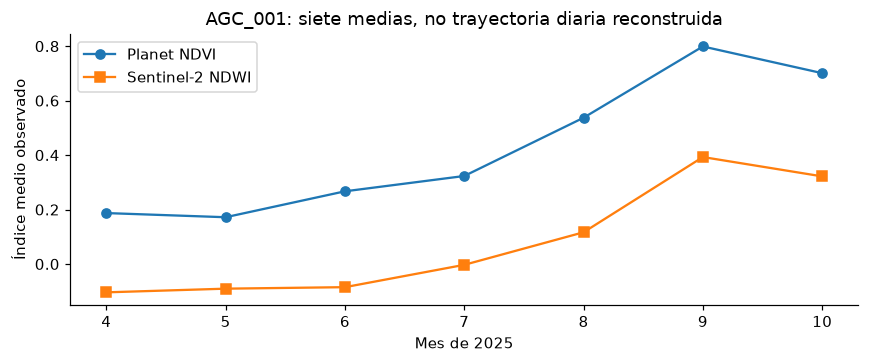

In [7]:
DIAS = pd.Series([30,31,30,31,31,30,31], index=range(4,11), name="dias_mes")

def medias_mensuales(datos, sensor, campo, ids):
    ids = list(ids)
    columnas = ["ID_POLIGONO", "sensor", "fecha_captura", campo]
    if not ids or len(set(ids)) != len(ids) or not set(columnas) <= set(datos):
        raise ValueError("IDs o columnas incompatibles")
    df = datos[columnas].copy()
    if df[columnas[:3]].isna().any().any() or set(df.ID_POLIGONO) != set(ids) or not df.sensor.eq(sensor).all():
        raise ValueError("ID, sensor o fecha incompatible")
    if not df.fecha_captura.astype(str).str.fullmatch(r"\d{2}/\d{2}/\d{4}").all():
        raise ValueError("Formato de fecha distinto de dd/mm/aaaa")
    df["fecha"] = pd.to_datetime(df.fecha_captura, format="%d/%m/%Y", errors="raise")
    if not df.fecha.between("2025-04-01", "2025-10-31").all() or df.duplicated(["ID_POLIGONO","sensor","fecha"]).any():
        raise ValueError("Ventana o duplicados incompatibles")
    df[campo] = pd.to_numeric(df[campo], errors="raise")
    q = df.dropna(subset=[campo]).copy()
    if not np.isfinite(q[campo].to_numpy(dtype=float)).all():
        raise ValueError("Valor presente no finito")
    q["mes"] = q.fecha.dt.month
    tabla = q.groupby(["ID_POLIGONO","mes"])[campo].agg(media="mean", n="count").reset_index()
    valores = tabla.pivot(index="ID_POLIGONO", columns="mes", values="media").reindex(index=ids, columns=DIAS.index)
    conteos = tabla.pivot(index="ID_POLIGONO", columns="mes", values="n").reindex(index=ids, columns=DIAS.index)
    if not np.isfinite(valores.to_numpy()).all() or not conteos.gt(0).all().all():
        raise ValueError("Mes ausente o sin valores; no se imputa ni renormaliza")
    tabla["sensor"], tabla["indice"] = sensor, campo
    tabla["dias_mes"] = tabla.mes.map(DIAS)
    return valores, tabla

ids_todos = X.ID_POLIGONO.tolist()
P, pm = medias_mensuales(planet, "Planet", "ndvi_promedio", ids_todos)
W, wm = medias_mensuales(s2, "Sentinel-2", "ndwi_promedio", ids_todos)
mensuales = pd.concat([pm,wm], ignore_index=True)
assert len(mensuales) == 197*2*7 == 2758
abril = planet.loc[planet.ID_POLIGONO.eq("AGC_001") & planet.fecha_captura.str.contains("/04/2025")]
display(abril[["fecha_captura","ndvi_promedio"]])
presentes = abril.ndvi_promedio.dropna().to_numpy(dtype=float)
np.testing.assert_allclose(presentes.sum()/len(presentes), P.loc["AGC_001",4], atol=1e-12, rtol=0)
ejemplo = mensuales.loc[mensuales.ID_POLIGONO.eq("AGC_001")]
display(ejemplo[["sensor","indice","mes","media","n","dias_mes"]])
figura, eje = plt.subplots(figsize=(8,3.4))
eje.plot(DIAS.index, P.loc["AGC_001"], "o-", label="Planet NDVI")
eje.plot(DIAS.index, W.loc["AGC_001"], "s-", label="Sentinel-2 NDWI")
eje.set(xlabel="Mes de 2025", ylabel="Índice medio observado", title="AGC_001: siete medias, no trayectoria diaria reconstruida")
eje.set_xticks(DIAS.index)
eje.legend()
figura.tight_layout()
plt.show()

## 4. Cuatro operaciones explícitas

Media del bimestre $B$: $\bar x_B=\sum_{m\in B}d_m\bar x_m/\sum_{m\in B}d_m$.
Primero agregamos por mes, después por días: no damos más peso a un mes por tener
más capturas. Jun–jul suma 61 días; jul–ago, 62. La amplitud es entre medias
**mensuales**, no el máximo de cada captura ni del píxel.

In [8]:
def media_periodo(mensual, meses):
    meses = list(meses)
    if not meses or len(set(meses)) != len(meses) or not set(meses) <= set(DIAS.index):
        raise ValueError("Periodo incompatible con la receta")
    valores = mensual[meses]
    if not np.isfinite(valores.to_numpy(dtype=float)).all():
        raise ValueError("Mes faltante o no finito en contraste")
    pesos = DIAS.loc[meses]
    return valores.mul(pesos, axis=1).sum(axis=1)/pesos.sum()

def descriptores_temporales(p, w):
    if not p.index.equals(w.index) or not p.columns.equals(DIAS.index) or not w.columns.equals(DIAS.index):
        raise ValueError("IDs o meses incompatibles entre series")
    if not np.isfinite(p.to_numpy()).all() or not np.isfinite(w.to_numpy()).all():
        raise ValueError("Curva mensual incompleta")
    nuevas = pd.DataFrame(index=p.index)
    nuevas[NEW[0]] = media_periodo(p,[6,7])-media_periodo(p,[4,5])
    nuevas[NEW[1]] = media_periodo(p,[9,10])-media_periodo(p,[7,8])
    nuevas[NEW[2]] = p.max(axis=1)-p.min(axis=1)
    nuevas[NEW[3]] = media_periodo(w,[9,10])-media_periodo(w,[7,8])
    return nuevas

nuevas = descriptores_temporales(P,W)
periodos = pd.DataFrame({"abr–may":media_periodo(P,[4,5]), "jun–jul":media_periodo(P,[6,7]),
                        "jul–ago":media_periodo(P,[7,8]), "sep–oct":media_periodo(P,[9,10])})
display(periodos.loc[["AGC_001"]])
# Comprobación manual de una resta y del intervalo mensual, sin etiquetas.
p = P.loc["AGC_001"]
manual = (p[6]*30+p[7]*31)/61-(p[4]*30+p[5]*31)/61
np.testing.assert_allclose(manual, nuevas.loc["AGC_001",NEW[0]], atol=1e-12, rtol=0)
np.testing.assert_allclose(p.max()-p.min(), nuevas.loc["AGC_001",NEW[2]], atol=1e-12, rtol=0)
display(nuevas.loc[["AGC_001"]].T.rename(columns={"AGC_001":"descriptor_calculado"}))
features = base.join(nuevas, validate="one_to_one")
assert features.shape == (197,12) and np.isfinite(features[OLD+NEW]).all().all()
display(features.head())

,abr–may,jun–jul,jul–ago,sep–oct
ID_POLIGONO,,,,
AGC_001,0.179337,0.295572,0.430205,0.749074


ID_POLIGONO,descriptor_calculado
PL_ndvi_junjul_menos_abrmay,0.116235
PL_ndvi_sepoct_menos_julago,0.318869
PL_ndvi_amplitud_mensual,0.627086
S2_ndwi_sepoct_menos_julago,0.299978


,Municipio,Estado,C_PL_ndvi_media,C_PL_ndvi_pico_prom,C_PL_ndvi_doy_pico_prom,C_S2_ndvi_media,C_S2_ndwi_media,C_LS_vi6t_media,PL_ndvi_junjul_menos_abrmay,PL_ndvi_sepoct_menos_julago,PL_ndvi_amplitud_mensual,S2_ndwi_sepoct_menos_julago
ID_POLIGONO,,,,,,,,,,,,
AGC_001,Calpulalpan,Tlaxcala,0.402093,0.836,245,0.338325,0.101100,-0.623929,0.116235,0.318869,0.627086,0.299978
AGC_002,Chignahuapan,Puebla,0.454918,0.835,184,0.402861,0.076472,-0.621455,0.392368,-0.160885,0.535679,-0.124504
AGC_003,Singuilucan,Hidalgo,0.463394,0.829,238,0.393629,0.063143,-0.645286,0.075992,0.090676,0.505182,0.062117
AGC_004,Calpulalpan,Tlaxcala,0.412143,0.700,245,0.311049,0.004902,-0.625833,0.157101,0.113858,0.448842,0.165804
AGC_005,Chignahuapan,Puebla,0.480924,0.871,248,0.396171,0.010200,-0.638115,0.207619,0.248855,0.582079,0.358155


**Control posterior:** recién ahora abrimos variables y meses guardados. Las seis
E2 proceden de la integración ya reconstruida; aquí las conservamos y contrastamos,
no volvemos a extraer geometrías ni las seis fuentes completas. Los campos de
geometría del control histórico no se incorporan a estos candidatos.

In [9]:
ctrl_features = leer_csv("variables_control","control_posterior").set_index("ID_POLIGONO")
assert ctrl_features.shape == (197,16) and ctrl_features.index.is_unique
assert set(ctrl_features.index) == set(features.index)
np.testing.assert_allclose(features[OLD+NEW].to_numpy(), ctrl_features.loc[ids_todos,OLD+NEW].to_numpy(), atol=1e-12, rtol=0)
np.testing.assert_array_equal(features[OLD].to_numpy(), base_x.loc[ids_todos,OLD].to_numpy())
pd.testing.assert_frame_equal(features[["Municipio","Estado"]], ctrl_features.loc[ids_todos,["Municipio","Estado"]])
ctrl_months = leer_csv("mensuales_control","control_posterior")
keys_month = ["ID_POLIGONO","sensor","indice","mes"]
a, b = mensuales.set_index(keys_month).sort_index(), ctrl_months.set_index(keys_month).sort_index()
assert a.index.is_unique and a.index.equals(b.index)
np.testing.assert_allclose(a.media,b.media,atol=1e-12,rtol=0)
np.testing.assert_array_equal(a[["n","dias_mes"]],b[["n","dias_mes"]])
print("2,758 medias y cuatro variables coinciden a 10⁻¹²; seis E2 originales intactas.")

2,758 medias y cuatro variables coinciden a 10⁻¹²; seis E2 originales intactas.


## 5. El diseño 2 × 2 evita confundir dos cambios

| | Seis originales + municipio | Añadir cuatro descriptores |
| --- | --- | --- |
| Ridge | R_B: control E2 | R_T |
| HGB | H_B | H_T |

R_T−R_B y H_T−H_B comparan el bloque dentro de un procedimiento. H_B−R_B y
H_T−R_T comparan procedimientos con las mismas entradas. No se atribuye una
diferencia que cambia ambos factores exclusivamente a las variables.

**Ridge** es lineal regularizado ([documentación oficial](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)).
**HGB** combina árboles mediante gradient boosting, una alternativa no lineal
([documentación oficial](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)).
No demuestra que alguna familia sea óptima.

Ambos: municipio one-hot completo; numéricas → mediana → escala → estimador.
Todo se aprende dentro de cada entrenamiento. Árboles no requieren escalado;
mantenerlo común evitó introducir otra diferencia. Municipio desconocido →
indicadores cero, no fallback explícito global como MUN.

In [10]:
variantes = MAN["variantes"]
display(pd.DataFrame([{"procedimiento":k,"algoritmo":v["algoritmo"],
                      "numéricas":len(v["variables"]),"municipio":True} for k,v in variantes.items()]))
display(pd.DataFrame([{"algoritmo":alg,"opción":i,"parámetros":json.dumps(params,sort_keys=True)}
                      for alg, grid in MAN["algoritmos"].items() for i,params in enumerate(grid)]))
display(pd.DataFrame([MAN["HGB_fijos"]]).T.rename(columns={0:"valor_fijo"}))
print("Ridge: cinco opciones; HGB: cuatro. No son presupuestos equivalentes ni búsqueda exhaustiva.")

,procedimiento,algoritmo,numéricas,municipio
0,R_B,Ridge,6,True
1,R_T,Ridge,10,True
2,H_B,HGB,6,True
3,H_T,HGB,10,True


,algoritmo,opción,parámetros
0,Ridge,0,"{""alpha"": 100.0}"
1,Ridge,1,"{""alpha"": 10.0}"
2,Ridge,2,"{""alpha"": 1.0}"
3,Ridge,3,"{""alpha"": 0.1}"
4,Ridge,4,"{""alpha"": 0.01}"
5,HGB,0,"{""max_leaf_nodes"": 3, ""min_samples_leaf"": 16}"
6,HGB,1,"{""max_leaf_nodes"": 3, ""min_samples_leaf"": 8}"
7,HGB,2,"{""max_leaf_nodes"": 7, ""min_samples_leaf"": 16}"
8,HGB,3,"{""max_leaf_nodes"": 7, ""min_samples_leaf"": 8}"


,valor_fijo
loss,squared_error
learning_rate,0.05
max_iter,100
max_bins,63
l2_regularization,1
early_stopping,False
categorical_features,None
random_state,20260929


Ridge: cinco opciones; HGB: cuatro. No son presupuestos equivalentes ni búsqueda exhaustiva.


## 6. Separar selección interior de evaluación exterior

FULL138, cinco pliegues × diez repeticiones; cuatro interiores por exterior.
Los CSV guardados son la autoridad: no buscamos otra semilla ni regeneramos roles.
Cada interior se contiene en el entrenamiento exterior; nunca incluye su evaluación.

In [11]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

**Selector:** RMSE de errores interiores concatenados, no media de cuatro RMSE.
Tolerancia 10⁻¹². La primera opción dentro del mínimo favorece Ridge alpha mayor;
HGB menos hojas y, a igual número, más observaciones por hoja. Verificamos decisiones
desde cinco/cuatro scores almacenados, no volvemos a calcular esos scores.

In [12]:
def seleccionar_parametros(algoritmo, scores):
    if algoritmo not in MAN["algoritmos"]:
        raise ValueError("Algoritmo fuera del protocolo")
    grid = MAN["algoritmos"][algoritmo]
    scores = np.asarray(scores,dtype=float)
    if scores.shape != (len(grid),) or not np.isfinite(scores).all() or (scores<0).any():
        raise ValueError("Scores incompatibles")
    elegido = int(np.flatnonzero(scores <= scores.min()+1e-12)[0])
    return grid[elegido]

seleccion = leer_csv("seleccion","scores_guardados")
assert len(seleccion) == 200 and set(seleccion.modelo) == set(variantes)
assert not seleccion.duplicated(["modelo","repeticion","pliegue"]).any()
exteriores = set(externas.groupby(["repeticion","pliegue"]).groups)
scores_verificados = 0
for nombre,g in seleccion.groupby("modelo"):
    assert len(g) == 50 and set(zip(g.repeticion,g.pliegue)) == exteriores
    alg = variantes[nombre]["algoritmo"]
    for _,fila in g.iterrows():
        scores = json.loads(fila.scores_internos)
        guardado = json.loads(fila.parametros)
        assert seleccionar_parametros(alg,scores) == guardado
        scores_verificados += len(scores)
assert scores_verificados == 900
ejemplo_seleccion = seleccion.loc[seleccion.repeticion.eq(0)&seleccion.pliegue.eq(0)]
display(ejemplo_seleccion)
print("200 decisiones / 900 scores guardados. No hay errores internos individuales para recalcular scores.")
print("Presupuesto histórico: 900 opciones × 4 interiores + 200 reajustes = 3,800. Actual: 0.")

,modelo,repeticion,pliegue,parametros,scores_internos
0,R_B,0,0,"{""alpha"": 0.1}","[0.724850903348099, 0.5437661596958524, 0.4769..."
50,R_T,0,0,"{""alpha"": 1.0}","[0.7045571061617846, 0.5477944775621053, 0.495..."
100,H_B,0,0,"{""max_leaf_nodes"": 3, ""min_samples_leaf"": 8}","[0.6265351308703805, 0.5450065854440871, 0.631..."
150,H_T,0,0,"{""max_leaf_nodes"": 3, ""min_samples_leaf"": 8}","[0.6022110210103193, 0.5429445165378299, 0.602..."


200 decisiones / 900 scores guardados. No hay errores internos individuales para recalcular scores.
Presupuesto histórico: 900 opciones × 4 interiores + 200 reajustes = 3,800. Actual: 0.


Anidar evita una fuga durante selección, pero no borra exploración previa sobre las
mismas 138 etiquetas. Elegir después el mejor de cuatro añade sesgo de selección.
Este resultado sigue siendo exploratorio, no una prueba confirmatoria independiente.

## 7. Control histórico y claves OOF

R_B reprodujo E2 antes de probar las otras variantes; las tres referencias también
se contrastaron contra sus OOF previas a 10⁻⁸ t/ha, con alphas E2 iguales. Hoy
cotejamos **registros guardados**; no reproducimos esos entrenamientos de nuevo.
MIX = 0.5 MUN + 0.5 IDW, k=20, potencia 2 y piso 1 m; coordenadas solo allí.

In [13]:
todos = leer_csv("oof","resultados_guardados")
modelos = ["GLOBAL","MUN","MIX","R_B","R_T","H_B","H_T"]
esperado = set(map(tuple,validaciones[claves].to_numpy()))
oficial = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
assert len(todos) == 9660 and set(todos.modelo) == set(modelos)
assert not todos.duplicated(["modelo"]+claves).any()
assert set(todos.ID_POLIGONO) == set(oficial.index)
for _,g in todos.groupby("modelo"):
    assert len(g) == 1380 and set(map(tuple,g[claves].to_numpy())) == esperado
    np.testing.assert_allclose(g.observado,g.ID_POLIGONO.map(oficial),atol=0,rtol=0)
    assert np.isfinite(g[["observado","predicho"]].to_numpy()).all()
    for campo in ["Municipio","Estado"]:
        np.testing.assert_array_equal(g[campo],g.ID_POLIGONO.map(base[campo]))
assert todos.zona.eq(np.where(todos.Municipio.eq("Chignahuapan"),"Chignahuapan","Resto")).all()
old_oof = leer_csv("oof_ronda1","resultados_guardados")
refs = leer_csv("referencias","resultados_guardados")
alias = {"GLOBAL":"Media global","MUN":"Media municipal","MIX":"Municipio + IDW fijo"}
controles_delta = {}
for actual,previo in {"R_B":"E2",**alias}.items():
    origen = old_oof if actual == "R_B" else refs
    a = todos.loc[todos.modelo.eq(actual)].set_index(claves).sort_index()
    b = origen.loc[origen.modelo.eq(previo)].set_index(claves).sort_index()
    assert a.index.is_unique and a.index.equals(b.index) and len(a) == 1380
    np.testing.assert_allclose(a.observado,b.observado,atol=0,rtol=0)
    np.testing.assert_allclose(a.predicho,b.predicho,atol=1e-8,rtol=0)
    controles_delta[actual] = float(np.abs(a.predicho-b.predicho).max())
alpha_previos = leer_csv("alpha_ronda1","scores_guardados").query("modelo == 'E2'")
rb = seleccion.query("modelo == 'R_B'").merge(alpha_previos,on=["repeticion","pliegue"],validate="one_to_one")
assert len(rb) == 50
assert all(json.loads(p)["alpha"] == a for p,a in zip(rb.parametros,rb.alpha,strict=True))
for _,fila in rb.iterrows():
    previo = [fila[f"rmse_interno_alpha_{p['alpha']:g}"] for p in MAN["algoritmos"]["Ridge"]]
    np.testing.assert_allclose(json.loads(fila.scores_internos),previo,atol=1e-8,rtol=0)
display(pd.Series(controles_delta,name="máximo_delta_OOF_guardadas"))
todos["error"] = todos.predicho-todos.observado
todos["error2"] = todos.error**2
print("9,660 OOF conciliadas, siete procedimientos, 138 etiquetas. Cero predicciones finales.")

R_B       4.396483e-14
GLOBAL    4.440892e-16
MUN       8.881784e-16
MIX       8.881784e-16
Name: máximo_delta_OOF_guardadas, dtype: float64

9,660 OOF conciliadas, siete procedimientos, 138 etiquetas. Cero predicciones finales.


## 8. Recalcular errores antes de abrir el control

Cada fila evalúa los mismos 1,380 errores de FULL138. RMSE/MAE en t/ha;
R² sin unidades. $RMSE=\sqrt{\overline{e^2}}$, $MAE=\overline{|e|}$,
$R^2=1-\sum e^2/\sum(y-\bar y)^2$. Denominador ≤10⁻¹² → NaN.
No promediar primero diez predicciones por parcela ni los RMSE de pliegues.

,RMSE,MAE,R2
GLOBAL,0.854426,0.753994,-0.015043
MUN,0.511757,0.335394,0.635865
MIX,0.493845,0.341711,0.660908
R_B,0.519202,0.359676,0.625193
R_T,0.529337,0.375885,0.610417
H_B,0.580418,0.415106,0.531600
H_T,0.576991,0.422852,0.537115


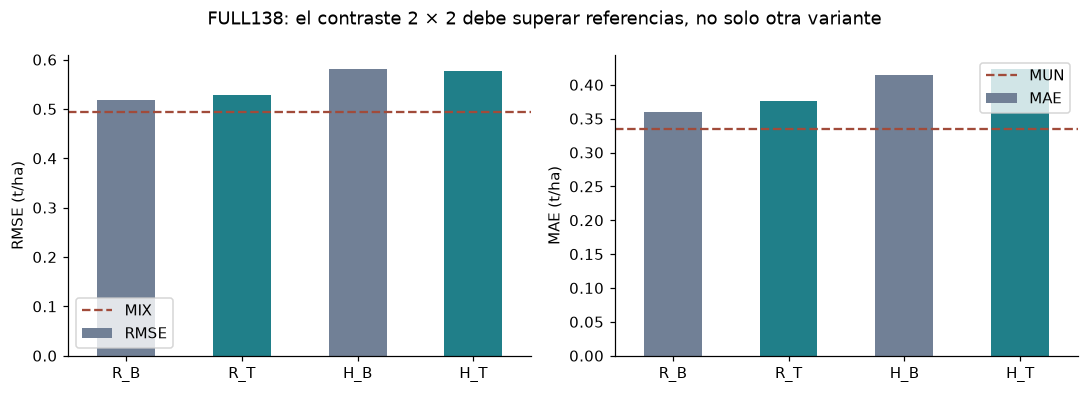

In [14]:
def metricas(df):
    y,p = df.observado.to_numpy(dtype=float),df.predicho.to_numpy(dtype=float)
    if len(y) == 0 or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Métrica vacía o no finita")
    e = p-y
    denom = np.sum((y-y.mean())**2)
    return pd.Series({"RMSE":np.sqrt(np.mean(e**2)),"MAE":np.mean(np.abs(e)),
                      "R2":1-np.sum(e**2)/denom if denom>1e-12 else np.nan})

resultados = pd.DataFrame({k:metricas(g) for k,g in todos.groupby("modelo")}).T.loc[modelos]
display(resultados.round(9))
figura,ejes = plt.subplots(1,2,figsize=(10,3.6))
candidatos = ["R_B","R_T","H_B","H_T"]
for eje,m in zip(ejes,["RMSE","MAE"]):
    resultados.loc[candidatos,m].plot.bar(ax=eje,color=["#718096","#207f89","#718096","#207f89"])
    referencia = "MIX" if m == "RMSE" else "MUN"
    eje.axhline(resultados.loc[referencia,m],color="#a14b3a",linestyle="--",label=referencia)
    eje.set_ylabel(m+" (t/ha)")
    eje.set_xlabel("")
    eje.tick_params(axis="x",rotation=0)
    eje.legend()
figura.suptitle("FULL138: el contraste 2 × 2 debe superar referencias, no solo otra variante")
figura.tight_layout()
plt.show()
control = leer_csv("metricas_control","control_posterior").set_index("modelo")
assert control.index.is_unique and set(control.index) == set(modelos)
np.testing.assert_allclose(resultados.to_numpy(),control.loc[modelos,["RMSE","MAE","R2"]].to_numpy(),atol=1e-12,rtol=0)

R_T empeora R_B: RMSE 0.5192 → 0.5293; MAE 0.3597 → 0.3759.
H_T baja RMSE de H_B: 0.5804 → 0.5770, pero sube MAE 0.4151 → 0.4229.
HGB queda por detrás de Ridge bajo estas rejillas. No equivale a demostrar
superioridad universal de Ridge ni inutilidad de los árboles.

## 9. Comparaciones pareadas y regla de avance

Negativo favorece al primer procedimiento. La regla original exigía RMSE menor
que MIX y MAE no mayor que MUN, con cada sentido en ≥8/10 repeticiones.
Es regla de desarrollo, no la rúbrica oficial ni significancia estadística.
Las diez repeticiones reutilizan datos: sus rangos no son intervalos de confianza.

In [15]:
rep = pd.DataFrame([{"modelo":k,"repeticion":r,**metricas(g).to_dict()}
                    for (k,r),g in todos.groupby(["modelo","repeticion"])])
rr = rep.pivot(index="repeticion",columns="modelo",values="RMSE")
rm = rep.pivot(index="repeticion",columns="modelo",values="MAE")
pares = MAN["comparaciones"]+[[k,b] for k in variantes for b in ["MUN","MIX"]]
contrastes = pd.DataFrame([{"modelo":k,"base":b,
    "delta_RMSE":resultados.loc[k,"RMSE"]-resultados.loc[b,"RMSE"],
    "delta_MAE":resultados.loc[k,"MAE"]-resultados.loc[b,"MAE"],
    "reps_menor_RMSE":int((rr[k]<rr[b]).sum()),
    "reps_menor_MAE":int((rm[k]<rm[b]).sum())} for k,b in pares])
display(contrastes)
ctrl_pares = leer_csv("contrastes_control","control_posterior").set_index(["modelo","base"])
actual = contrastes.set_index(["modelo","base"])
assert actual.index.is_unique and set(actual.index) == set(ctrl_pares.index)
np.testing.assert_allclose(actual.to_numpy(),ctrl_pares.loc[actual.index,actual.columns].to_numpy(),atol=1e-12,rtol=0)
regla = pd.DataFrame([{"procedimiento":k,
    "RMSE_menor_MIX":bool(resultados.loc[k,"RMSE"]<resultados.loc["MIX","RMSE"]),
    "MAE_no_mayor_MUN":bool(resultados.loc[k,"MAE"]<=resultados.loc["MUN","MAE"]),
    "reps_RMSE_menor_MIX":int((rr[k]<rr.MIX).sum()),
    "reps_MAE_no_mayor_MUN":int((rm[k]<=rm.MUN).sum())} for k in variantes]).set_index("procedimiento")
regla["cumple"] = regla.RMSE_menor_MIX & regla.MAE_no_mayor_MUN & regla.reps_RMSE_menor_MIX.ge(8) & regla.reps_MAE_no_mayor_MUN.ge(8)
assert not regla.cumple.any()
display(regla)

,modelo,base,delta_RMSE,delta_MAE,reps_menor_RMSE,reps_menor_MAE
0,R_T,R_B,0.010135,0.016209,1,0
1,H_T,H_B,-0.003427,0.007747,6,3
2,H_B,R_B,0.061216,0.055430,0,0
3,H_T,R_T,0.047654,0.046967,0,0
4,R_B,MUN,0.007445,0.024282,1,0
5,R_B,MIX,0.025357,0.017965,0,0
6,R_T,MUN,0.017580,0.040491,0,0
7,R_T,MIX,0.035492,0.034174,0,0
8,H_B,MUN,0.068661,0.079711,0,0
9,H_B,MIX,0.086573,0.073395,0,0


,RMSE_menor_MIX,MAE_no_mayor_MUN,reps_RMSE_menor_MIX,reps_MAE_no_mayor_MUN,cumple
procedimiento,,,,,
R_B,False,False,0,0,False
R_T,False,False,0,0,False
H_B,False,False,0,0,False
H_T,False,False,0,0,False


El bloque mejora RMSE de Ridge solo en 1/10; con HGB en 6/10, pero empeora
MAE global. **Ninguna variante cumple la regla**. No rescatamos la prueba eligiendo
solo su métrica favorable.

## 10. Territorio y dependencia de dos focos

Conservamos 71 parcelas de Chignahuapan y 67 del resto. La sensibilidad sin
AGC_127/171 ya estaba prevista; modifica solo puntuación, no entrenamiento.
No elimina supuestos datos malos ni sirve para escoger otro modelo por región.

In [16]:
zonas = pd.DataFrame([{"modelo":k,"zona":z,"parcelas":g.ID_POLIGONO.nunique(),**metricas(g).to_dict()}
                      for (k,z),g in todos.groupby(["modelo","zona"])])
display(zonas.loc[zonas.modelo.isin(candidatos+["MIX"])])
ep = todos.groupby(["ID_POLIGONO","modelo"]).error2.mean().unstack()
ep["delta_Ridge"] = ep.R_T-ep.R_B
ep["delta_HGB"] = ep.H_T-ep.H_B
focos = ["AGC_127","AGC_171"]
display(ep[["delta_Ridge","delta_HGB"]].loc[focos])
display(pd.DataFrame({"mejoran":[int(ep[c].lt(0).sum()) for c in ["delta_Ridge","delta_HGB"]],
    "empeoran":[int(ep[c].gt(0).sum()) for c in ["delta_Ridge","delta_HGB"]],
    "suma_delta_MSE":[ep[c].sum() for c in ["delta_Ridge","delta_HGB"]]},index=["Ridge","HGB"]))
print("ΔMSE: error cuadrático medio por parcela; suma en (t/ha)², no ΔSSE de 1,380 OOF.")
sin_focos = todos.loc[~todos.ID_POLIGONO.isin(focos)]
sensibilidad = pd.DataFrame({k:metricas(g) for k,g in sin_focos.groupby("modelo")}).T.loc[modelos]
display(sensibilidad)
control_sens = leer_csv("sensibilidad_control","control_posterior").set_index("modelo")
np.testing.assert_allclose(sensibilidad.to_numpy(),control_sens.loc[modelos,["RMSE","MAE","R2"]].to_numpy(),atol=1e-12,rtol=0)
assert sin_focos.ID_POLIGONO.nunique() == 136 and len(sin_focos) == 7*1360
assert resultados.loc["H_T","RMSE"]<resultados.loc["H_B","RMSE"]
assert sensibilidad.loc["H_T","RMSE"]>sensibilidad.loc["H_B","RMSE"]

,modelo,zona,parcelas,RMSE,MAE,R2
2,H_B,Chignahuapan,71,0.614848,0.412252,-0.122751
3,H_B,Resto,67,0.541549,0.418129,0.446572
4,H_T,Chignahuapan,71,0.606899,0.424724,-0.093906
5,H_T,Resto,67,0.543505,0.420869,0.442568
6,MIX,Chignahuapan,71,0.573628,0.389104,0.022745
7,MIX,Resto,67,0.391961,0.291488,0.710085
10,R_B,Chignahuapan,71,0.603285,0.399641,-0.080918
11,R_B,Resto,67,0.411769,0.317325,0.680042
12,R_T,Chignahuapan,71,0.602822,0.405011,-0.079261
13,R_T,Resto,67,0.438216,0.345020,0.637621


modelo,delta_Ridge,delta_HGB
ID_POLIGONO,,
AGC_127,-0.305317,-0.326448
AGC_171,-0.204756,-0.632949


,mejoran,empeoran,suma_delta_MSE
Ridge,60,78,1.466513
HGB,60,78,-0.547378


ΔMSE: error cuadrático medio por parcela; suma en (t/ha)², no ΔSSE de 1,380 OOF.


,RMSE,MAE,R2
GLOBAL,0.835003,0.739821,-0.015386
MUN,0.464585,0.314856,0.685670
MIX,0.452476,0.322915,0.701841
R_B,0.468523,0.338457,0.680319
R_T,0.483784,0.356254,0.659153
H_B,0.541243,0.396300,0.573381
H_T,0.544034,0.406566,0.568969


Al puntuar las otras 136, se invierte la pequeña mejora HGB: H_B RMSE 0.541243;
H_T 0.544034. Los dos focos compensaban deterioros del resto. Es sensibilidad
exploratoria prevista, no una validación independiente ni una propuesta de retirarlos.
Para Ridge, el cambio en Chignahuapan es pequeño (0.6033 → 0.6028) y fuera
empeora (0.4118 → 0.4382): no hay avance territorial uniforme.

## 11. Decisión y siguiente pregunta

**Cierre conservado: no adoptar el bloque ni reemplazar las referencias.**
R_T empeora; H_T intercambia una reducción frágil de RMSE por mayor MAE.
Ninguno supera la regla frente a MIX/MUN. Se conserva la prueba negativa.

Límite: solo estas cuatro variables, calendarios, rejillas, una temporada y
FULL138. No descarta clima, nuevas representaciones, otras familias o calidad.
No demuestra causalidad ni extrapolación. Tampoco confunde fidelidad de cálculo
con validación agronómica o desempeño oficial en las 59 parcelas.

**Continuidad:** evaluar otra hipótesis concreta de representación, con sus
referencias y reglas propias. La siguiente ronda histórica aborda lluvia de
octubre; no la incorporamos a V1 ni anticipamos su resultado.

Registro local: 29/sep; ejecución: noche del 29 en México, 30 en UTC; adaptación:
8/oct. Hash identifica bytes, no certifica anterioridad externa ni acuerdo del equipo.

In [17]:
resumen = {"id":"EXP_03","modo":"lector_retrospectivo_sin_ajustes",
    "parcelas":197,"etiquetas":138,"medias_mensuales":len(mensuales),
    "variables_base":OLD,"variables_nuevas":NEW,"procedimientos":7,
    "oof_por_procedimiento":1380,"oof_total":len(todos),
    "particiones_externas":50,"particiones_internas":200,
    "decisiones_verificadas":len(seleccion),"scores_guardados_verificados":scores_verificados,
    "ajustes_actuales":0,"predicciones_finales_generadas":0,"poblacion":"FULL138",
    "scores_interiores_recalculados":False,"predicciones_recalculadas":False,
    "variables_recalculadas":True,"metricas_recalculadas":True,"variantes_adoptadas":[],
    "fecha_original":"2026-09-29","fecha_adaptacion":"2026-10-08",
    "metricas":resultados.to_dict(orient="index"),"fecha_ejecucion_utc":FECHA_EJECUCION_UTC}
print("RESUMEN_EXP_03_JSON="+json.dumps(resumen,sort_keys=True))
print("Cierre: cuatro variables y resultados históricos conciliados; cero ajustes actuales.")

RESUMEN_EXP_03_JSON={"ajustes_actuales": 0, "decisiones_verificadas": 200, "etiquetas": 138, "fecha_adaptacion": "2026-10-08", "fecha_ejecucion_utc": "2026-10-08T14:36:29.400134+00:00", "fecha_original": "2026-09-29", "id": "EXP_03", "medias_mensuales": 2758, "metricas": {"GLOBAL": {"MAE": 0.7539942301985781, "R2": -0.015042909859176445, "RMSE": 0.854426183817986}, "H_B": {"MAE": 0.4151055109566083, "R2": 0.5315998662085495, "RMSE": 0.580417974167716}, "H_T": {"MAE": 0.4228522569433367, "R2": 0.5371148390308235, "RMSE": 0.5769909177212699}, "MIX": {"MAE": 0.34171071524357766, "R2": 0.6609083799141342, "RMSE": 0.4938452449320778}, "MUN": {"MAE": 0.33539413463469375, "R2": 0.6358645937936154, "RMSE": 0.5117570123866723}, "R_B": {"MAE": 0.3596758963638445, "R2": 0.6251928722045933, "RMSE": 0.5192018945322401}, "R_T": {"MAE": 0.3758849321129275, "R2": 0.6104173695212822, "RMSE": 0.529336864636895}}, "metricas_recalculadas": true, "modo": "lector_retrospectivo_sin_ajustes", "oof_por_procedi

## Referencias y glosario breve

**Descriptor:** resumen definido de una curva. **Diseño 2 × 2:** cruzar dos
representaciones con dos procedimientos para separar comparaciones.
**HGB:** gradient boosting con árboles e histogramas. **Ridge:** regresión lineal L2.
**OOF:** predicción guardada para una parcela apartada. **Selección interior:**
elegir parámetros sin usar la evaluación exterior. **Sensibilidad:** cambiar una
condición explícita de puntuación, no ocultar casos para promover un resultado.

scikit-learn developers. (s. f.). *Ridge* [Documentación de software].
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

scikit-learn developers. (s. f.). *HistGradientBoostingRegressor* [Documentación de software].
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html

**Evidencia incorporada del equipo:** protocolo, manifiesto `V1_temporal_2x2`,
registro y tablas, 29/sep/2026 en México; controles E2 y referencias. Los contratos
del cuaderno identifican sus bytes. No hace falta abrir otros archivos para seguirlo.